---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 18 (Tandborste)

- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)
- Name (NIM)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pemesanan membuat hotel kehilangan pendapatan dan menyulitkan perencanaan kamar. Notebook ini membangun
model klasifikasi biner yang memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled = 1`) dari atribut
pemesanan: jumlah tamu, lama menginap, jarak hari antara pemesanan dan kedatangan, tanggal kedatangan, harga per malam,
riwayat tamu, permintaan khusus, paket makan, kategori kamar, dan kanal pemesanan.

### Klasifikasi Pembatalan Pemesanan Hotel

Kelompok 18 (Tandborste). Target klasifikasi biner: `is_canceled` (1 = pemesanan dibatalkan).

## Aim

- Mengimplementasikan lima model dari nol (from scratch, NumPy): KNN, Decision Tree (C4.5), Logistic Regression,
  SVM, dan Naive Bayes.
- Membandingkan setiap model dengan padanannya di scikit-learn memakai protokol evaluasi yang sama.
- Memilih model from scratch terbaik untuk submission Kaggle, lalu menganalisis kesalahan prediksinya dan dampak
  biaya salah klasifikasi.

## Metric

Metrik utama adalah **Macro F1** (metrik Kaggle): rata-rata F1 kelas 0 (tidak batal) dan F1 kelas 1 (batal). Kelas
batal hanya sekitar 33% data, sehingga akurasi bisa tinggi walaupun banyak pembatalan terlewat; Macro F1 memberi bobot
yang sama pada kedua kelas. Setiap model dinilai dengan rata-rata Macro F1 5-fold `StratifiedKFold` pada train split
dan Macro F1 pada hold-out 20% (`val_set`).

Biaya kesalahan: salah memprediksi batal (FP) berbiaya 2, salah memprediksi tidak batal (FN) berbiaya 1.

## Dataset

- `train.csv`: 27.373 pemesanan, 17 fitur (14 numerik, 3 kategorik), kolom `id`, dan target `is_canceled`
  (32,8% batal).
- `test.csv`: 6.844 pemesanan tanpa target, hanya untuk submission Kaggle.
- Beberapa kolom memiliki nilai kosong (paling banyak `num_children` sekitar 11%), dan ada baris duplikat serta baris
  tanpa tamu. Setelah `clean_train`, seluruh `train.csv` tersisa 27.309 baris.

Kolom numerik: `num_adults`, `num_children`, `weekend_nights`, `weekday_nights`, `needs_parking`,
`days_before_arrival`, `arrival_year`, `arrival_month`, `arrival_day`, `is_returning_guest`, `prior_cancellations`,
`prior_completed_bookings`, `nightly_rate_idr`, `special_requests`. Kolom kategorik: `meal_package`,
`room_category`, `booking_channel`.

## Approach

1. `train.csv` dibagi 80/20 secara stratified (seed 42). Cleaning (duplikat dan baris tanpa tamu) hanya dilakukan
   pada bagian train, dan semua statistik preprocessing dipelajari dari bagian train saja.
2. Dua pipeline preprocessing:
   - **pipeline numerik** (KNN, Logistic Regression, SVM): fitur turunan, indikator missing, imputasi median,
     clipping outlier, grouping kategori langka, standardisasi, one-hot encoding, dan opsional seleksi fitur atau PCA;
   - **pipeline tree** (Decision Tree, Naive Bayes): fitur turunan dan grouping kategori langka; nilai kosong dan
     kategori ditangani langsung oleh model.
3. Hyperparameter dan threshold tiap model diambil dari eksperimen tim (`output/*.csv`), lalu dievaluasi ulang di
   notebook ini dengan `cross_validate` 5-fold dan hold-out, berdampingan dengan versi scikit-learn.
4. Model from scratch dengan Macro F1 CV dan hold-out tertinggi di-fit ulang pada seluruh `train.csv` yang sudah
   dibersihkan untuk submission Kaggle, lalu dianalisis kesalahannya.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Import Libraries

Every import of the notebook is kept in this cell.

In [3]:
import os
import pickle
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone as sk_clone
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import accuracy_score, f1_score as sk_f1, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split as sk_train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src import config
from src.config import SEED
from src.data import CATEGORICAL_COLS, NUMERICAL_COLS, load_test, load_train
from src.evaluation.cost_sensitive import (
    bayes_optimal_threshold,
    cost_sensitive_class_weight,
    tune_threshold,
)
from src.evaluation.metrics import (
    accuracy,
    classification_report,
    confusion_matrix,
    f1_score,
    macro_f1,
    misclassification_cost,
    precision,
    recall,
    roc_auc,
)
from src.evaluation.model_selection import (
    StratifiedKFold,
    cross_validate,
    grid_search,
    train_test_split,
)
from src.models.decision_tree import DecisionTree
from src.models.knn import KNN
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import NaiveBayes
from src.models.svm import SVM
from src.preprocessing.cleaning import clean_train
from src.preprocessing.presets import make_numeric_pipeline, make_tree_pipeline, to_model_input
from src.preprocessing.resampling import RandomOverSampler, RandomUnderSampler, SMOTE
from src.preprocessing.transformation import (
    PCA,
    FeatureEngineer,
    MissingIndicator,
    MissingValueImputer,
    OneHotEncoder,
    OutlierClipper,
    StandardScaler,
    TreeInputFormatter,
)
from src.submission import make_submission, validate_submission
from src.visualization.decision_tree_graph import plot_decision_tree

# Tambahan untuk model, eksperimen tim, dan visualisasi bonus.
import hashlib
import json

from IPython.display import Image, display
from sklearn.datasets import make_classification

from src.experiments.decision_tree import GRID_PARAM_SPACE
from src.experiments.logistic_regression import _params_from_row, _sklearn_model, save_contour_gif
from src.experiments.svm_experiments import BEST_SVM_PARAMS, _sklearn_counterpart
from src.models.logistic_regression import AdamLogisticRegression
from src.preprocessing.transformation import RareCategoryGrouper
from src.visualization.naive_bayes_graph import plot_naive_bayes_graph
from src.visualization.svm_boundary import plot_svm_kernels

# src.visualization.svm_boundary dan logreg_contour memanggil matplotlib.use("Agg") saat di-import,
# sehingga backend inline dipasang kembali agar grafik tetap tampil di notebook.
%matplotlib inline

## Settings

Paths and shared constants are kept in this class.

In [4]:
class Settings:
    SEED           = config.SEED
    DATA_DIR       = config.DATA_DIR
    OUTPUT_DIR     = config.OUTPUT_DIR
    FIGURE_DIR     = config.FIGURE_DIR
    MODEL_DIR      = config.MODEL_DIR
    SUBMISSION_DIR = config.SUBMISSION_DIR

CFG = Settings()
for directory in (CFG.OUTPUT_DIR, CFG.FIGURE_DIR, CFG.MODEL_DIR, CFG.SUBMISSION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

### Plot Style and Helpers

In [5]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#b9b8b2"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)


def save_fig(fig, name):
    path = config.FIGURE_DIR / f"{name}.png"
    fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()
    print(f"Disimpan: {path.relative_to(config.ROOT_DIR)}")

## Seed Everything

A fixed seed keeps the results reproducible.

In [6]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)
print("SEED =", CFG.SEED)

SEED = 42


## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [7]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


In [8]:
X_raw, y_raw = load_train()
X_test_raw, ids = load_test()

---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

### Ukuran data

In [9]:
print(f"Train: {X_raw.shape[0]} baris, {X_raw.shape[1]} fitur")
print(f"Test : {X_test_raw.shape[0]} baris, {X_test_raw.shape[1]} fitur")
print(f"Kolom numerik   ({len(NUMERICAL_COLS)}): {NUMERICAL_COLS}")
print(f"Kolom kategorik ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")
X_raw.head()

Train: 27373 baris, 17 fitur
Test : 6844 baris, 17 fitur
Kolom numerik   (14): ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Kolom kategorik (3): ['meal_package', 'room_category', 'booking_channel']


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
0,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0
1,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0
2,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0
3,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0
4,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0


### Statistik deskriptif

In [10]:
X_raw[NUMERICAL_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.85,0.52,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,0.12,0.43,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,0.81,0.88,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.21,1.42,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,0.03,0.17,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,85.38,85.97,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2023.82,0.38,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.40,3.07,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,15.54,8.77,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,0.03,0.16,0.0,0.0,0.0,0.0,1.0


In [11]:
X_raw[CATEGORICAL_COLS].describe().T

,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


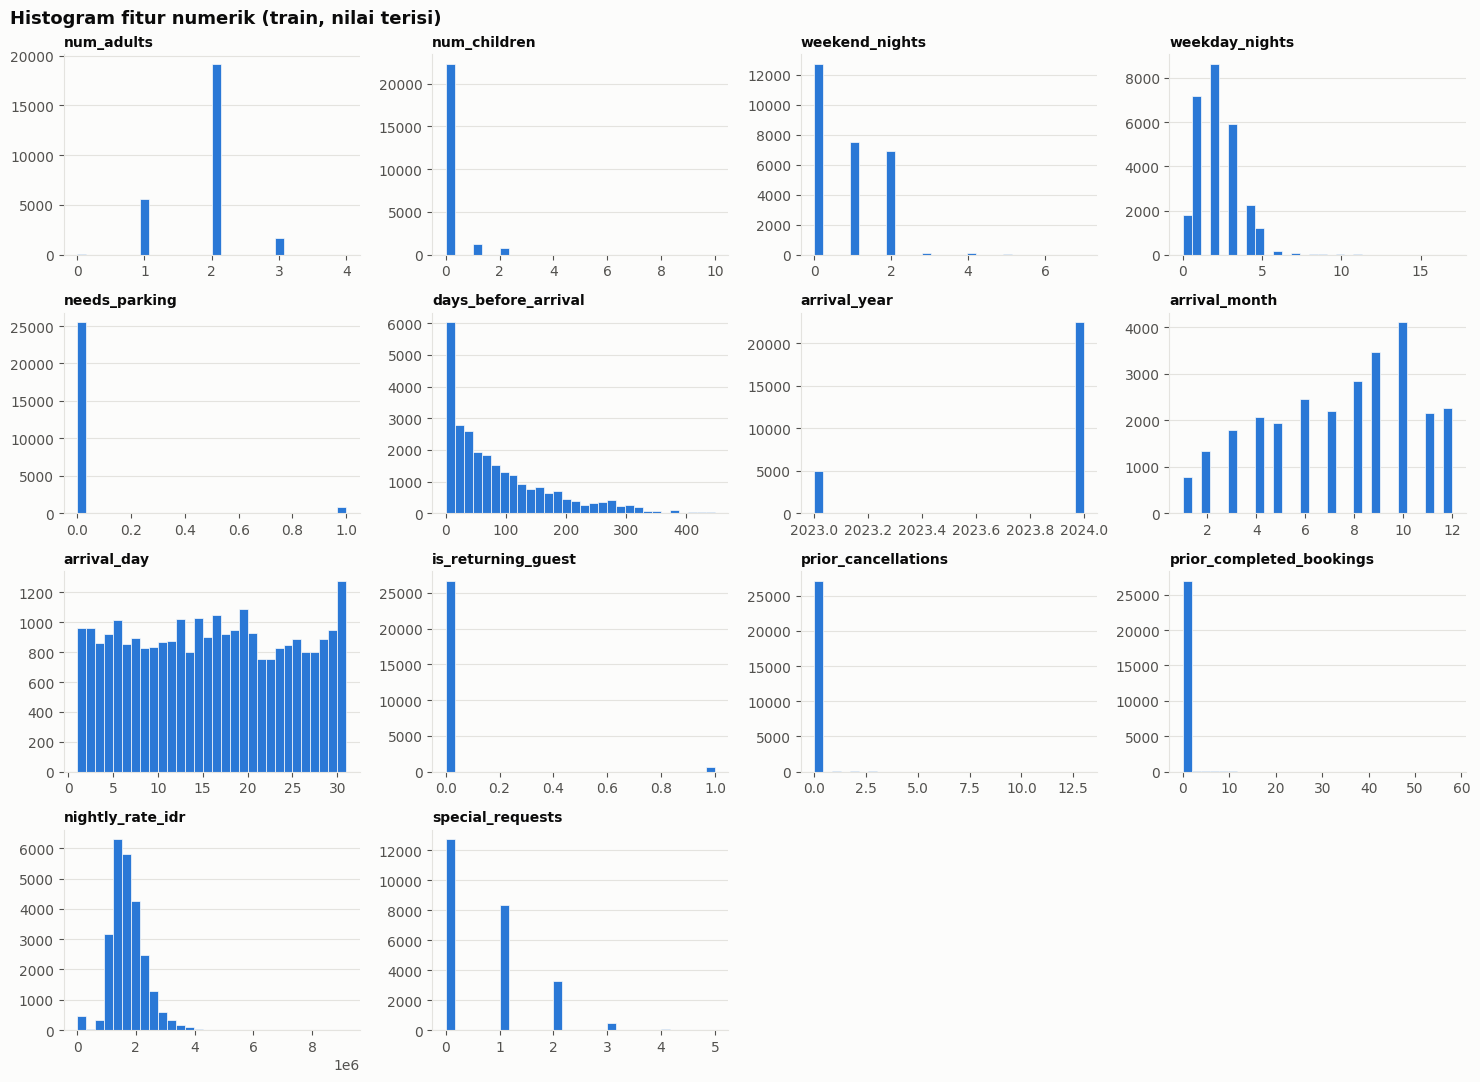

Disimpan: output/figures/eda_numeric_histograms.png


In [12]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUMERICAL_COLS):
    ax.hist(X_raw[col].dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(NUMERICAL_COLS):]:
    ax.set_visible(False)
fig.suptitle("Histogram fitur numerik (train, nilai terisi)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig(fig, "eda_numeric_histograms")

## Explore Data

This part covers distributions and relationships between attributes.

### Distribusi target

             jumlah  proporsi
is_canceled                  
0             18404    0.6723
1              8969    0.3277


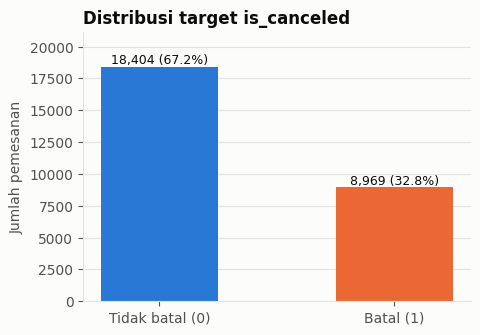

Disimpan: output/figures/eda_target_distribution.png


In [13]:
target_counts = y_raw.value_counts().sort_index()
target_share = y_raw.value_counts(normalize=True).sort_index()
print(pd.DataFrame({"jumlah": target_counts, "proporsi": target_share.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Tidak batal (0)", "Batal (1)"], target_counts.to_numpy(), color=[BLUE, ORANGE], width=0.5)
for bar, share in zip(bars, target_share.to_numpy()):
    ax.annotate(f"{bar.get_height():,.0f} ({share:.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, target_counts.max() * 1.15)
ax.set_ylabel("Jumlah pemesanan")
ax.set_title("Distribusi target is_canceled")
ax.grid(axis="x", visible=False)
save_fig(fig, "eda_target_distribution")

### Distribusi kategori

In [14]:
for col in CATEGORICAL_COLS:
    print(f"--- {col}")
    print(pd.DataFrame({
        "train": X_raw[col].value_counts(dropna=False),
        "test": X_test_raw[col].value_counts(dropna=False),
    }).fillna(0).astype(int))

--- meal_package
              train  test
meal_package             
Breakfast     19654  4940
Room Only      3713   918
Half Board     2242   543
NaN            1760   442
Full Board        4     1
--- room_category
               train  test
room_category             
Type A           699   192
Type B         20447  5096
Type C           189    47
Type D           514   127
Type E             7     0
Type F           119    25
Type G          4396  1115
NaN             1002   242
--- booking_channel
                     train  test
booking_channel                 
Online Travel Agent  17511  4363
Offline Agent         7960  1982
Corporate             1513   394
Complimentary          301    72
Airline                 88    33


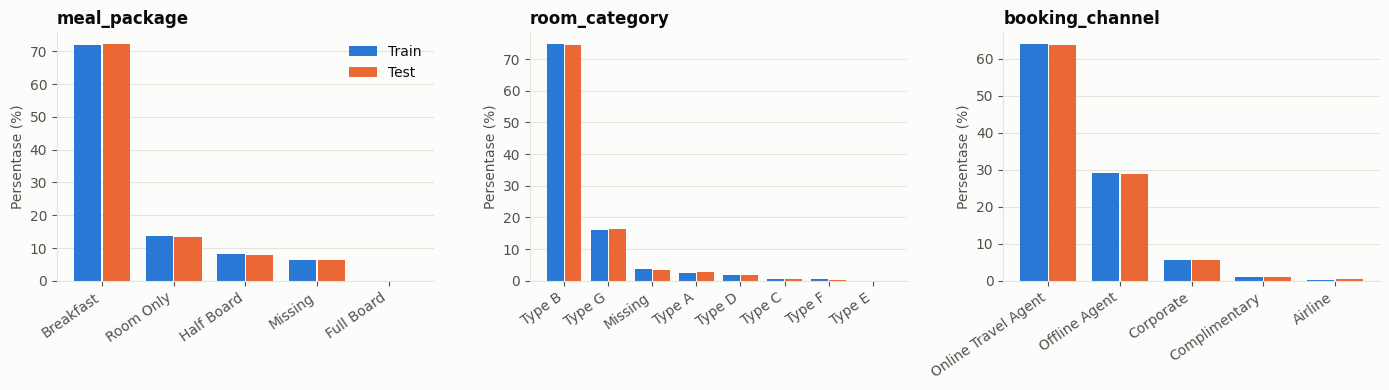

Disimpan: output/figures/eda_categorical_distribution.png


In [15]:
fig, axes = plt.subplots(1, len(CATEGORICAL_COLS), figsize=(14, 4))
for ax, col in zip(axes, CATEGORICAL_COLS):
    tr = X_raw[col].fillna("Missing").value_counts(normalize=True)
    te = X_test_raw[col].fillna("Missing").value_counts(normalize=True)
    order = tr.index.tolist() + [c for c in te.index if c not in tr.index]
    pos = np.arange(len(order))
    ax.bar(pos - 0.2, tr.reindex(order).fillna(0) * 100, width=0.38, color=BLUE, label="Train")
    ax.bar(pos + 0.2, te.reindex(order).fillna(0) * 100, width=0.38, color=ORANGE, label="Test")
    ax.set_xticks(pos, order, rotation=35, ha="right")
    ax.set_title(col)
    ax.set_ylabel("Persentase (%)")
    ax.grid(axis="x", visible=False)
axes[0].legend()
fig.tight_layout()
save_fig(fig, "eda_categorical_distribution")

### Tingkat batal per kategori

Tingkat batal keseluruhan: 32.77%
--- meal_package
             rate      n
Half Board  45.94   2242
Room Only   33.80   3713
Missing     31.93   1760
Breakfast   31.14  19654
Full Board  25.00      4
--- room_category


          rate      n
Type A   42.63    699
Missing  34.83   1002
Type G   34.19   4396
Type D   32.88    514
Type B   32.14  20447
Type E   28.57      7
Type C   24.87    189
Type F   24.37    119
--- booking_channel
                      rate      n
Online Travel Agent  36.37  17511
Airline              30.68     88
Offline Agent        30.15   7960
Corporate            11.50   1513
Complimentary         0.00    301


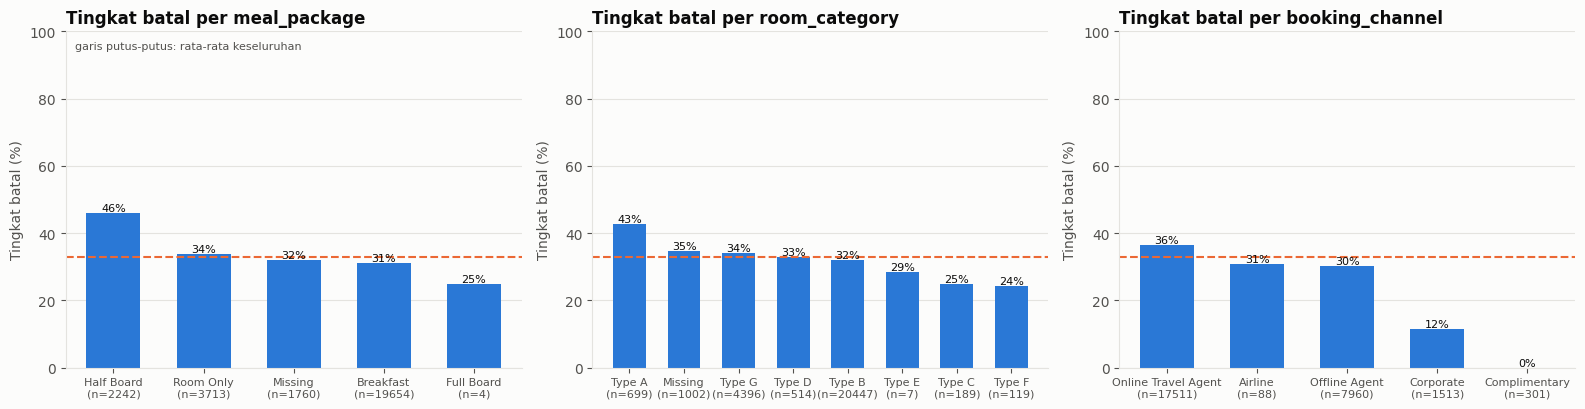

Disimpan: output/figures/eda_cancel_rate_by_category.png


In [16]:
base_rate = y_raw.mean()


def rate_table(feature, numeric=False):
    def label(v):
        if pd.isna(v):
            return "Missing"
        if isinstance(v, (int, float, np.integer, np.floating)) and float(v).is_integer():
            return str(int(v))
        return str(v)

    keys = X_raw[feature].map(label).to_numpy()
    table = y_raw.groupby(keys).agg(rate="mean", n="size")
    if numeric:
        order = sorted(table.index, key=lambda k: (k == "Missing", float(k) if k != "Missing" else 0.0))
        return table.loc[order]
    return table.sort_values("rate", ascending=False)


def plot_rates(ax, table, title):
    pos = np.arange(len(table))
    ax.bar(pos, table["rate"] * 100, width=0.6, color=BLUE)
    ax.axhline(base_rate * 100, color=ORANGE, linewidth=1.5, linestyle="--")
    for p, (rate, n) in enumerate(zip(table["rate"], table["n"])):
        ax.annotate(f"{rate:.0%}", (p, rate * 100), ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(pos, [f"{k}\n(n={n})" for k, n in zip(table.index, table["n"])], fontsize=8)
    ax.set_ylim(0, max(100, table["rate"].max() * 100 * 1.15))
    ax.set_ylabel("Tingkat batal (%)")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)


print(f"Tingkat batal keseluruhan: {base_rate:.2%}")
for col in CATEGORICAL_COLS:
    print(f"--- {col}")
    print(rate_table(col).assign(rate=lambda t: (t.rate * 100).round(2)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, CATEGORICAL_COLS):
    plot_rates(ax, rate_table(col), f"Tingkat batal per {col}")
axes[0].annotate("garis putus-putus: rata-rata keseluruhan", (0.02, 0.97), xycoords="axes fraction",
                 fontsize=8, color=MUTED, va="top")
fig.tight_layout()
save_fig(fig, "eda_cancel_rate_by_category")

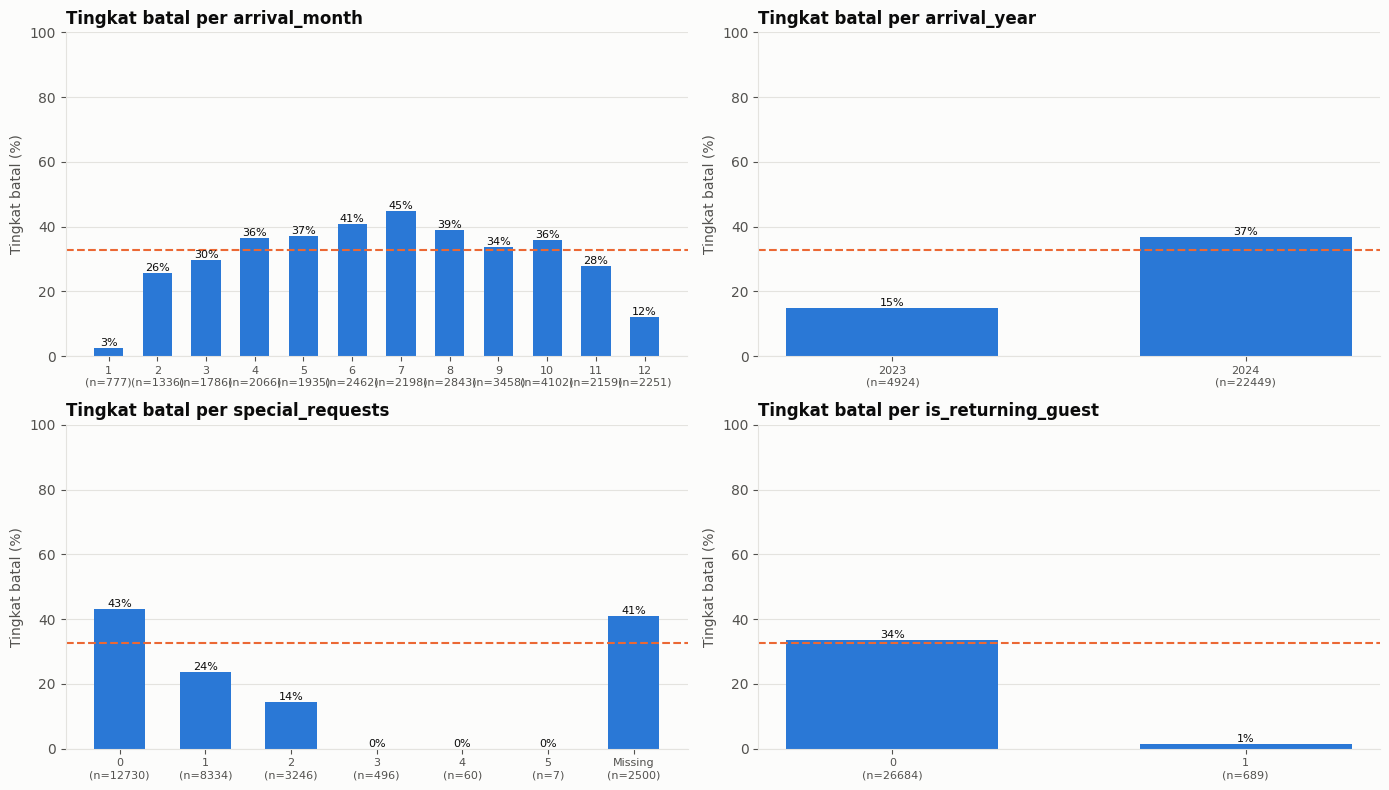

Disimpan: output/figures/eda_cancel_rate_by_discrete_features.png


In [17]:
discrete = ["arrival_month", "arrival_year", "special_requests", "is_returning_guest"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), discrete):
    plot_rates(ax, rate_table(col, numeric=True), f"Tingkat batal per {col}")
fig.tight_layout()
save_fig(fig, "eda_cancel_rate_by_discrete_features")

### Korelasi fitur numerik dengan target

days_before_arrival         0.4403
special_requests           -0.2580
arrival_year                0.1798
nightly_rate_idr            0.1341
is_returning_guest         -0.1072
weekday_nights              0.0972
num_adults                  0.0884
needs_parking              -0.0855
weekend_nights              0.0608
prior_completed_bookings   -0.0589
prior_cancellations        -0.0350
num_children                0.0309
arrival_day                 0.0200
arrival_month              -0.0159
Name: is_canceled, dtype: float64


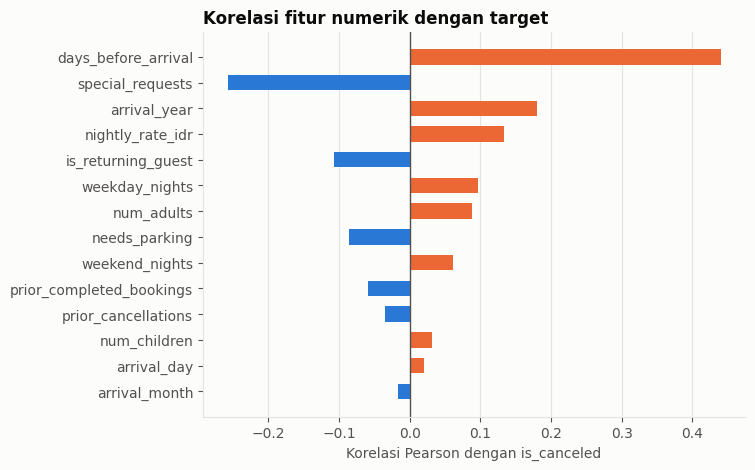

Disimpan: output/figures/eda_numeric_correlation_with_target.png


In [18]:
corr = pd.concat([X_raw[NUMERICAL_COLS], y_raw], axis=1).corr()[config.TARGET_COL].drop(config.TARGET_COL)
corr = corr.reindex(corr.abs().sort_values().index)
print(corr.sort_values(key=abs, ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.to_numpy(), height=0.6, color=[ORANGE if v > 0 else BLUE for v in corr])
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Korelasi Pearson dengan is_canceled")
ax.set_title("Korelasi fitur numerik dengan target")
ax.grid(axis="y", visible=False)
save_fig(fig, "eda_numeric_correlation_with_target")

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

### Missing values per kolom (train vs test)

In [19]:
missing = pd.DataFrame(
    {
        "train_n": X_raw.isna().sum(),
        "train_pct": (X_raw.isna().mean() * 100).round(2),
        "test_n": X_test_raw.isna().sum(),
        "test_pct": (X_test_raw.isna().mean() * 100).round(2),
    }
)
print(f"Kolom dengan missing: {(missing.train_n > 0).sum()} dari {len(missing)}")
missing[(missing.train_n > 0) | (missing.test_n > 0)].sort_values("train_pct", ascending=False)

Kolom dengan missing: 8 dari 17


,train_n,train_pct,test_n,test_pct
num_children,3035,11.09,747,10.91
special_requests,2500,9.13,593,8.66
nightly_rate_idr,2038,7.45,540,7.89
meal_package,1760,6.43,442,6.46
days_before_arrival,1123,4.10,290,4.24
needs_parking,1082,3.95,247,3.61
room_category,1002,3.66,242,3.54
num_adults,809,2.96,180,2.63


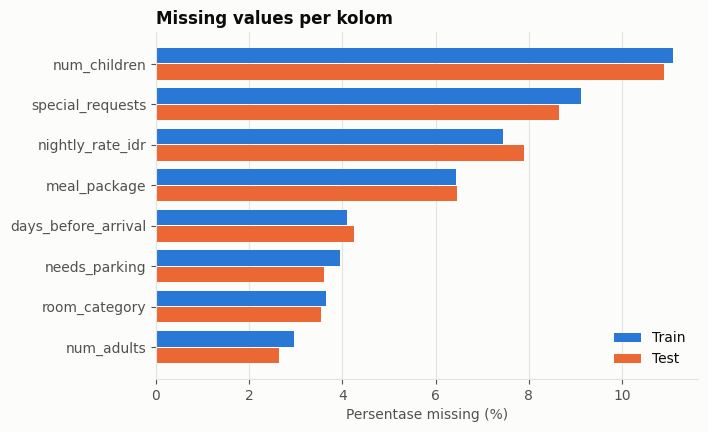

Disimpan: output/figures/eda_missing_values_train_vs_test.png


In [20]:
with_missing = missing[(missing.train_n > 0) | (missing.test_n > 0)].sort_values("train_pct")
pos = np.arange(len(with_missing))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(pos + 0.2, with_missing["train_pct"], height=0.38, color=BLUE, label="Train")
ax.barh(pos - 0.2, with_missing["test_pct"], height=0.38, color=ORANGE, label="Test")
ax.set_yticks(pos, with_missing.index)
ax.set_xlabel("Persentase missing (%)")
ax.set_title("Missing values per kolom")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig(fig, "eda_missing_values_train_vs_test")

### Tingkat batal saat kolom kosong vs terisi

In [21]:
rows = []
for col in X_raw.columns[X_raw.isna().any()]:
    is_missing = X_raw[col].isna()
    rows.append(
        {
            "kolom": col,
            "n_kosong": int(is_missing.sum()),
            "batal_saat_kosong": y_raw[is_missing].mean(),
            "batal_saat_terisi": y_raw[~is_missing].mean(),
        }
    )
missing_effect = pd.DataFrame(rows).set_index("kolom")
missing_effect["selisih"] = missing_effect["batal_saat_kosong"] - missing_effect["batal_saat_terisi"]
missing_effect.round(4)

,n_kosong,batal_saat_kosong,batal_saat_terisi,selisih
kolom,,,,
num_adults,809,0.3350,0.3274,0.0075
num_children,3035,0.3282,0.3276,0.0006
meal_package,1760,0.3193,0.3282,-0.0089
needs_parking,1082,0.3124,0.3283,-0.0159
room_category,1002,0.3483,0.3269,0.0214
days_before_arrival,1123,0.3117,0.3283,-0.0167
nightly_rate_idr,2038,0.3131,0.3288,-0.0158
special_requests,2500,0.4084,0.3195,0.0889


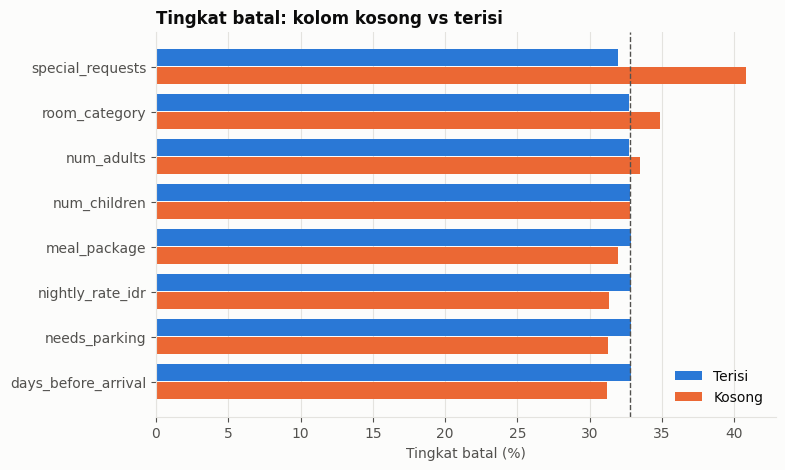

Disimpan: output/figures/eda_cancel_rate_missing_vs_filled.png


In [22]:
plot_df = missing_effect.sort_values("selisih")
pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pos + 0.2, plot_df["batal_saat_terisi"] * 100, height=0.38, color=BLUE, label="Terisi")
ax.barh(pos - 0.2, plot_df["batal_saat_kosong"] * 100, height=0.38, color=ORANGE, label="Kosong")
ax.axvline(base_rate * 100, color=MUTED, linewidth=1, linestyle="--")
ax.set_yticks(pos, plot_df.index)
ax.set_xlabel("Tingkat batal (%)")
ax.set_title("Tingkat batal: kolom kosong vs terisi")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save_fig(fig, "eda_cancel_rate_missing_vs_filled")

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [23]:
X_train_raw, X_val, y_train_raw, y_val = sk_train_test_split(
    X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=CFG.SEED
)
train_set = (X_train_raw, y_train_raw)
val_set = (X_val, y_val)

print(f"Train split     : {len(X_train_raw)} baris")
print(f"Validation split: {len(X_val)} baris")
print(pd.DataFrame({
    "train": y_train_raw.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
}).round(4))

Train split     : 21898 baris
Validation split: 5475 baris
              train  validation
is_canceled                    
0            0.6723      0.6723
1            0.3277      0.3277


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [24]:
# Seleksi record: clean_train membuang duplikat persis (fitur + target) dan baris tanpa tamu, hanya pada train split.
# Rinciannya ada di subbagian Duplicates dan Data Errors.
X_clean, y_clean = clean_train(X_train_raw, y_train_raw)

# Seleksi atribut: ke-17 fitur dipakai. Kolom id sudah dibuang oleh load_train karena hanya pengenal baris.
X_selected = X_clean[NUMERICAL_COLS + CATEGORICAL_COLS]
print(f"Train split: {X_train_raw.shape} -> sesudah seleksi record dan atribut: {X_selected.shape}")
print("Kolom fitur yang dibuang:", sorted(set(X_clean.columns) - set(X_selected.columns)) or "tidak ada")
X_selected.head(3)

Train split: (21898, 17) -> sesudah seleksi record dan atribut: (21858, 17)
Kolom fitur yang dibuang: tidak ada


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,room_category,booking_channel
0,2.0,0.0,2,0,0.0,388.0,2024,10,22,0,0,0,NaN,1.0,Half Board,Type B,Offline Agent
1,2.0,0.0,1,2,0.0,306.0,2024,11,3,0,0,0,1501000.0,NaN,Breakfast,Type B,Online Travel Agent
2,1.0,0.0,0,2,0.0,166.0,2023,10,2,0,0,0,1620000.0,0.0,Breakfast,Type B,Offline Agent


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [25]:
indicator = MissingIndicator(NUMERICAL_COLS).fit(X_clean)
imputer = MissingValueImputer(NUMERICAL_COLS, CATEGORICAL_COLS).fit(X_clean)
X_imputed = imputer.transform(indicator.transform(X_clean))

missing_cols = [c for c in X_clean.columns if X_clean[c].isna().any()]
missing_summary = pd.DataFrame(
    {
        "n_kosong": X_clean[missing_cols].isna().sum(),
        "pct_kosong": (X_clean[missing_cols].isna().mean() * 100).round(2),
        "nilai_isi_dari_train": [imputer.fill_values_.get(c, imputer.categorical_fill) for c in missing_cols],
    }
)
print("Indikator missing yang ditambahkan:", indicator.feature_names_)
print(f"Shape: {X_clean.shape} -> {X_imputed.shape}")
print(f"NaN sebelum: {int(X_clean.isna().sum().sum())} | NaN sesudah imputasi: {int(X_imputed.isna().sum().sum())}")
missing_summary

Indikator missing yang ditambahkan: ['num_adults__was_missing', 'num_children__was_missing', 'needs_parking__was_missing', 'days_before_arrival__was_missing', 'nightly_rate_idr__was_missing', 'special_requests__was_missing']
Shape: (21858, 17) -> (21858, 23)
NaN sebelum: 10644 | NaN sesudah imputasi: 0


,n_kosong,pct_kosong,nilai_isi_dari_train
num_adults,636,2.91,2.0
num_children,2426,11.10,0.0
meal_package,1403,6.42,Missing
needs_parking,885,4.05,0.0
room_category,810,3.71,Missing
days_before_arrival,875,4.00,57.0
nightly_rate_idr,1594,7.29,1647000.0
special_requests,2015,9.22,0.0


### Duplicates

This part covers repeated records.

In [26]:
keyed = X_train_raw.assign(**{config.TARGET_COL: y_train_raw.to_numpy()})
print(f"Sebelum cleaning (train split)        : {len(X_train_raw)} baris")
print(f"Duplikat persis (fitur + target)      : {int(keyed.duplicated(keep='first').sum())}")
print(f"Duplikat fitur saja (target bisa beda): {int(X_train_raw.duplicated(keep='first').sum())}")
print(f"Sesudah cleaning (train split)        : {len(X_clean)} baris")
print(f"Baris dibuang (duplikat + tanpa tamu) : {len(X_train_raw) - len(X_clean)}")
print("Distribusi target sesudah cleaning:")
print(y_clean.value_counts().sort_index().to_string())

Sebelum cleaning (train split)        : 21898 baris
Duplikat persis (fitur + target)      : 40
Duplikat fitur saja (target bisa beda): 41
Sesudah cleaning (train split)        : 21858 baris
Baris dibuang (duplikat + tanpa tamu) : 40
Distribusi target sesudah cleaning:
is_canceled
0    14696
1     7162


### Outliers

This part covers values far from the rest of the data.

In [27]:
clip_cols = ["nightly_rate_idr", "days_before_arrival", "weekend_nights", "weekday_nights",
             "num_children", "num_adults", "prior_cancellations", "prior_completed_bookings"]
clipper = OutlierClipper(clip_cols, upper_quantile=0.99).fit(X_clean)
X_clipped = clipper.transform(X_clean)

before = X_clean[clip_cols].apply(pd.to_numeric, errors="coerce")
upper = pd.Series(clipper.upper_)
outlier_summary = pd.DataFrame(
    {
        "batas_atas_q99_train": upper,
        "maks_sebelum": before.max(),
        "maks_sesudah": X_clipped[clip_cols].max(),
        "n_dipotong": (before > upper).sum(),
    }
)
print(f"Nilai yang dipotong: {int(outlier_summary['n_dipotong'].sum())} dari {int(before.notna().sum().sum())} nilai terisi")
outlier_summary.round(2)

Nilai yang dipotong: 1221 dari 169333 nilai terisi


,batas_atas_q99_train,maks_sebelum,maks_sesudah,n_dipotong
nightly_rate_idr,3442740.0,9165000.0,3442740.0,203
days_before_arrival,344.0,448.0,344.0,206
weekend_nights,2.0,7.0,2.0,213
weekday_nights,6.0,17.0,6.0,201
num_children,2.0,10.0,2.0,15
num_adults,3.0,4.0,3.0,10
prior_cancellations,0.0,13.0,0.0,183
prior_completed_bookings,4.0,58.0,4.0,190


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

Rows with zero guests (`num_adults + num_children == 0`) are impossible values. They are removed together with the duplicates by `clean_train` in the Duplicates part above.

In [28]:
raw_guests = X_train_raw["num_adults"] + X_train_raw["num_children"]
clean_guests = X_clean["num_adults"] + X_clean["num_children"]
print(f"Baris tanpa tamu: train split {int((raw_guests == 0).sum())} -> sesudah clean_train {int((clean_guests == 0).sum())}")
print("Nilai negatif di kolom numerik:", int((X_clean[NUMERICAL_COLS] < 0).sum().sum()))

arrival = pd.to_datetime(
    pd.DataFrame({"year": X_clean["arrival_year"], "month": X_clean["arrival_month"], "day": X_clean["arrival_day"]}),
    errors="coerce",
)
print(f"Tanggal kedatangan tidak valid (misalnya 29 Februari pada tahun non-kabisat): {int(arrival.isna().sum())} baris;")
print("  fitur tanggal turunannya menjadi NaN di FeatureEngineer lalu diimputasi oleh pipeline.")
print("Nilai unik kolom kategorik (train split):")
for col in CATEGORICAL_COLS:
    print(f"  {col}: {sorted(X_clean[col].dropna().unique().tolist())}")

Baris tanpa tamu: train split 0 -> sesudah clean_train 0
Nilai negatif di kolom numerik: 0
Tanggal kedatangan tidak valid (misalnya 29 Februari pada tahun non-kabisat): 0 baris;
  fitur tanggal turunannya menjadi NaN di FeatureEngineer lalu diimputasi oleh pipeline.
Nilai unik kolom kategorik (train split):
  meal_package: ['Breakfast', 'Full Board', 'Half Board', 'Room Only']
  room_category: ['Type A', 'Type B', 'Type C', 'Type D', 'Type E', 'Type F', 'Type G']
  booking_channel: ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [29]:
engineer = FeatureEngineer().fit(X_clean)
X_constructed = engineer.transform(X_clean)
print(f"Shape: {X_clean.shape} -> {X_constructed.shape}")
print("Atribut baru:", FeatureEngineer.ENGINEERED_COLS)

constructed_summary = X_constructed[FeatureEngineer.ENGINEERED_COLS].describe().T[["count", "mean", "std", "min", "max"]]
constructed_summary["korelasi_dengan_target"] = X_constructed[FeatureEngineer.ENGINEERED_COLS].corrwith(y_clean)
constructed_summary.round(3)

Shape: (21858, 17) -> (21858, 24)
Atribut baru: ['total_nights', 'total_guests', 'has_children', 'is_free', 'total_cost', 'arrival_dayofweek', 'arrival_is_weekend']


,count,mean,std,min,max,korelasi_dengan_target
total_nights,21858.0,3.017,1.804,0.0,24.0,0.104
total_guests,18868.0,1.968,0.665,1.0,12.0,0.078
has_children,19432.0,0.083,0.276,0.0,1.0,0.025
is_free,20264.0,0.016,0.125,0.0,1.0,-0.087
total_cost,20264.0,5199289.232,3609721.696,0.0,55370000.0,0.156
arrival_dayofweek,21858.0,3.080,2.067,0.0,6.0,0.032
arrival_is_weekend,21858.0,0.319,0.466,0.0,1.0,0.029


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [30]:
# Standardisasi z = (x - mean_train) / std_train. src.preprocessing hanya menyediakan standardisasi; normalisasi
# min-max tidak dipakai karena satu outlier ekstrem akan menekan nilai lain ke rentang yang sempit.
scaler = StandardScaler(NUMERICAL_COLS).fit(X_imputed)
X_scaled = scaler.transform(X_imputed)
scaling_summary = pd.DataFrame(
    {
        "mean_dari_train": pd.Series(scaler.mean_),
        "std_dari_train": pd.Series(scaler.std_),
        "mean_sesudah": X_scaled[NUMERICAL_COLS].mean(),
        "std_sesudah": X_scaled[NUMERICAL_COLS].std(ddof=0),
    }
)
scaling_summary.round(3)

,mean_dari_train,std_dari_train,mean_sesudah,std_sesudah
num_adults,1.852,0.512,0.0,1.0
num_children,0.105,0.407,-0.0,1.0
weekend_nights,0.818,0.875,-0.0,1.0
weekday_nights,2.198,1.421,0.0,1.0
needs_parking,0.029,0.169,-0.0,1.0
days_before_arrival,83.873,84.245,-0.0,1.0
arrival_year,2023.820,0.384,0.0,1.0
arrival_month,7.395,3.077,0.0,1.0
arrival_day,15.540,8.772,-0.0,1.0
is_returning_guest,0.025,0.156,-0.0,1.0


### Encoding

This part covers the numeric representation of categorical attributes.

In [31]:
grouper = RareCategoryGrouper(CATEGORICAL_COLS).fit(X_imputed)
X_grouped = grouper.transform(X_imputed)
encoder = OneHotEncoder(CATEGORICAL_COLS).fit(X_grouped)
X_encoded = encoder.transform(X_grouped)

for col in CATEGORICAL_COLS:
    print(f"{col}: {X_imputed[col].nunique()} kategori -> {len(encoder.categories_[col])} kolom one-hot "
          f"(kategori dengan < {grouper.min_count} baris digabung menjadi '{grouper.other_label}')")
print(f"Shape: {X_grouped.shape} -> {X_encoded.shape}")
X_encoded[encoder.feature_names_].head(3)

meal_package: 5 kategori -> 5 kolom one-hot (kategori dengan < 20 baris digabung menjadi 'Other')
room_category: 8 kategori -> 8 kolom one-hot (kategori dengan < 20 baris digabung menjadi 'Other')
booking_channel: 5 kategori -> 5 kolom one-hot (kategori dengan < 20 baris digabung menjadi 'Other')
Shape: (21858, 23) -> (21858, 38)


,meal_package__Breakfast,meal_package__Half Board,meal_package__Missing,meal_package__Other,meal_package__Room Only,room_category__Missing,room_category__Other,room_category__Type A,room_category__Type B,room_category__Type C,room_category__Type D,room_category__Type F,room_category__Type G,booking_channel__Airline,booking_channel__Complimentary,booking_channel__Corporate,booking_channel__Offline Agent,booking_channel__Online Travel Agent
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

The reduction steps below start from the full numeric feature matrix, fitted on the training split only.

In [32]:
base_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
Xn_train = base_pipeline.fit_transform(X_clean, y_clean)
print(f"Matriks fitur sebelum reduksi: {Xn_train.shape}")

Matriks fitur sebelum reduksi: (21858, 45)


### Pipeline numerik dengan seleksi fitur (select_k=20)

In [33]:
selection_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, select_k=20)
Xs_train = selection_pipeline.fit_transform(X_clean, y_clean)
selector = dict(selection_pipeline.steps)["selector"]

print(f"Sebelum seleksi: {Xn_train.shape[1]} kolom | sesudah seleksi: {Xs_train.shape[1]} kolom")
print("Kolom terpilih:", ", ".join(selector.selected_features_))

scores = pd.Series(selector.scores_).sort_values(ascending=False)
print(f"Kolom lolos filter variansi dan korelasi: {len(scores)}")
print(f"Kolom disingkirkan filter: {sorted(set(Xn_train.columns) - set(scores.index))}")
scores.round(5).to_frame("skor_mutual_info").head(20)

Sebelum seleksi: 45 kolom | sesudah seleksi: 20 kolom
Kolom terpilih: num_adults, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, is_returning_guest, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, is_free, total_cost, special_requests__was_missing, meal_package__Breakfast, meal_package__Half Board, booking_channel__Complimentary, booking_channel__Corporate, booking_channel__Online Travel Agent
Kolom lolos filter variansi dan korelasi: 44
Kolom disingkirkan filter: ['prior_cancellations']


,skor_mutual_info
days_before_arrival,0.09710
special_requests,0.03709
arrival_year,0.01882
arrival_month,0.01748
nightly_rate_idr,0.01621
total_cost,0.01489
total_nights,0.00934
is_returning_guest,0.00839
prior_completed_bookings,0.00790
booking_channel__Corporate,0.00680


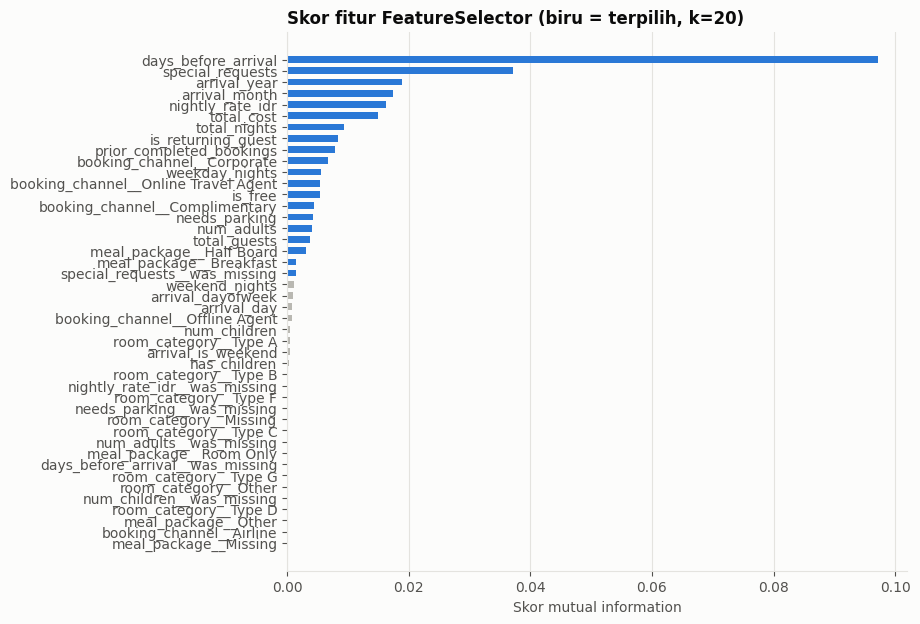

Disimpan: output/figures/prep_feature_selection_scores.png


In [34]:
ranked = scores.sort_values()
chosen = set(selector.selected_features_)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(ranked.index, ranked.to_numpy(), height=0.6, color=[BLUE if c in chosen else NEUTRAL for c in ranked.index])
ax.set_xlabel("Skor mutual information")
ax.set_title("Skor fitur FeatureSelector (biru = terpilih, k=20)")
ax.grid(axis="y", visible=False)
save_fig(fig, "prep_feature_selection_scores")

### PCA

In [35]:
pca_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, use_pca=True)
Xp_train = pca_pipeline.fit_transform(X_clean, y_clean)
Xp_test = pca_pipeline.transform(X_test_raw)
pca_step = dict(pca_pipeline.steps)["pca"]

print(f"Sebelum PCA: {Xn_train.shape[1]} kolom | sesudah PCA (varians 95%): {Xp_train.shape[1]} komponen")
print(f"Total varians terjelaskan: {pca_step.explained_variance_ratio_.sum():.4f}")
print(f"Train: {Xp_train.shape}, Test: {Xp_test.shape}")
Xp_train.head()

Sebelum PCA: 45 kolom | sesudah PCA (varians 95%): 18 komponen
Total varians terjelaskan: 0.9547
Train: (21858, 18), Test: (6844, 18)


,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10,pc11,pc12,pc13,pc14,pc15,pc16,pc17,pc18
0,-0.141435,-0.479692,-0.717729,-1.561947,-0.122043,0.214476,1.459618,2.435155,1.043289,1.369401,2.043654,0.803998,0.022642,-0.927928,-0.380157,-0.759909,-0.252536,-0.134351
1,-0.123488,-0.501150,2.391162,0.313697,-0.588610,0.195233,0.800248,1.960138,-1.160786,1.175389,0.863869,0.897965,0.344269,0.152544,0.013937,1.066352,0.408311,0.002230
2,-2.116802,-0.924996,-0.723543,-1.089813,-2.287694,0.332640,-1.455461,1.084398,-1.020454,0.611900,-0.125378,-0.953831,-0.111957,-1.188580,0.215963,0.171288,0.042050,0.274842
3,-1.229666,0.607021,2.099196,0.255347,-0.394276,0.714648,-0.354758,0.344196,-1.579195,-0.117354,-0.303600,0.422299,0.459027,1.560773,0.552837,-0.232869,0.292817,0.110969
4,0.495376,-0.142790,0.131498,-0.269565,0.907393,-0.579235,-0.703572,-0.061528,-0.902539,-0.657113,-0.973199,-1.189855,0.711271,-0.057358,-0.159567,0.227529,0.746123,0.047271


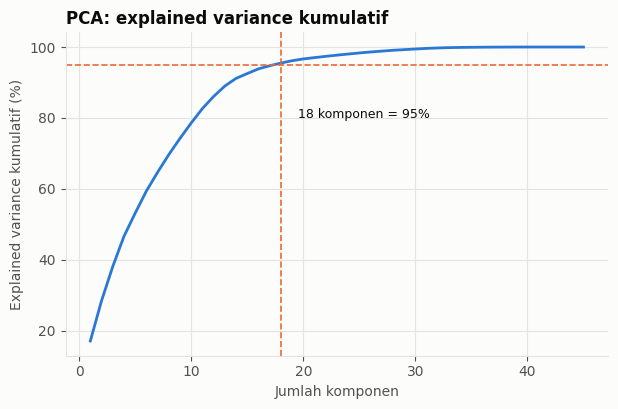

Disimpan: output/figures/prep_pca_cumulative_variance.png


In [36]:
full_pca = PCA(n_components=None).fit(Xn_train)
cumulative = np.cumsum(full_pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative * 100, color=BLUE)
ax.axhline(95, color=ORANGE, linewidth=1.2, linestyle="--")
ax.axvline(n95, color=ORANGE, linewidth=1.2, linestyle="--")
ax.annotate(f"{n95} komponen = 95%", (n95, 95), xytext=(n95 + 1.5, 80), fontsize=9, color=INK)
ax.set_xlabel("Jumlah komponen")
ax.set_ylabel("Explained variance kumulatif (%)")
ax.set_title("PCA: explained variance kumulatif")
save_fig(fig, "prep_pca_cumulative_variance")

## Class Balance

This part covers the proportion of each class in the training data.

### Resampling (hanya untuk data train)

In [37]:
A = Xn_train.to_numpy(dtype=float)
b = y_clean.to_numpy()

resamplers = {
    "Tanpa resampling": None,
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy=1.0),
    "RandomOverSampler": RandomOverSampler(sampling_strategy=1.0),
    "SMOTE": SMOTE(sampling_strategy=1.0, k_neighbors=5),
}
rows = {}
for name, resampler in resamplers.items():
    if resampler is None:
        A_res, b_res = A, b
    else:
        A_res, b_res = resampler.fit_resample(A, b)
    counts = np.bincount(b_res.astype(int), minlength=2)
    rows[name] = {"kelas_0": int(counts[0]), "kelas_1": int(counts[1]), "total": len(b_res),
                  "n_kolom": A_res.shape[1], "rasio_1:0": round(counts[1] / counts[0], 3)}
resample_table = pd.DataFrame(rows).T
resample_table

,kelas_0,kelas_1,total,n_kolom,rasio_1:0
Tanpa resampling,14696.0,7162.0,21858.0,45.0,0.487
RandomUnderSampler,7162.0,7162.0,14324.0,45.0,1.000
RandomOverSampler,14696.0,14696.0,29392.0,45.0,1.000
SMOTE,14696.0,14696.0,29392.0,45.0,1.000


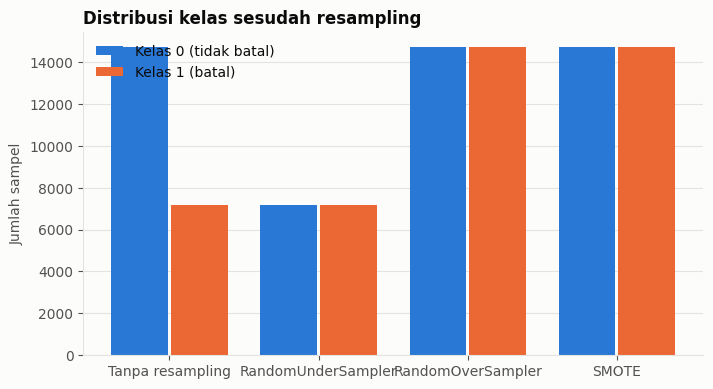

Disimpan: output/figures/prep_resampling_class_distribution.png


In [38]:
pos = np.arange(len(resample_table))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(pos - 0.2, resample_table["kelas_0"], width=0.38, color=BLUE, label="Kelas 0 (tidak batal)")
ax.bar(pos + 0.2, resample_table["kelas_1"], width=0.38, color=ORANGE, label="Kelas 1 (batal)")
ax.set_xticks(pos, resample_table.index)
ax.set_ylabel("Jumlah sampel")
ax.set_title("Distribusi kelas sesudah resampling")
ax.grid(axis="x", visible=False)
ax.legend()
save_fig(fig, "prep_resampling_class_distribution")

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [39]:
formatter = TreeInputFormatter(NUMERICAL_COLS, CATEGORICAL_COLS).fit(X_clean)
X_formatted = formatter.transform(X_clean)
X_matrix, cat_idx = to_model_input(X_formatted, CATEGORICAL_COLS)
print(f"Input Decision Tree / Naive Bayes: {X_matrix.shape}, dtype {X_matrix.dtype}, indeks kategorik {cat_idx}, "
      f"NaN dibiarkan ({int(X_formatted.isna().sum().sum())} sel)")

X_num_matrix, num_cat_idx = to_model_input(Xn_train, CATEGORICAL_COLS)
print(f"Input KNN / LR / SVM             : {X_num_matrix.shape}, dtype {X_num_matrix.dtype}, indeks kategorik {num_cat_idx}, "
      f"NaN {int(np.isnan(X_num_matrix).sum())}")
print("Contoh baris input tree:", X_matrix[0])

Input Decision Tree / Naive Bayes: (21858, 17), dtype object, indeks kategorik [14, 15, 16], NaN dibiarkan (10644 sel)
Input KNN / LR / SVM             : (21858, 45), dtype float64, indeks kategorik [], NaN 0
Contoh baris input tree: [2.0 0.0 2.0 0.0 0.0 388.0 2024.0 10.0 22.0 0.0 0.0 0.0 nan 1.0
 'Half Board' 'Type B' 'Offline Agent']


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

### Pipeline numerik (KNN, Logistic Regression, SVM)

Pipeline di-fit **hanya** pada data train, lalu `transform` dipakai untuk data test.

In [40]:
numeric_pipeline = make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
print("Langkah:", [name for name, _ in numeric_pipeline.steps])

Xn_train = numeric_pipeline.fit_transform(X_clean, y_clean)
Xn_test = numeric_pipeline.transform(X_test_raw)

print(f"Train: {Xn_train.shape}, Test: {Xn_test.shape}")
print(f"Jumlah kolom: {Xn_train.shape[1]}")
print(", ".join(Xn_train.columns))
print("Kolom train == test:", list(Xn_train.columns) == list(Xn_test.columns))
print("NaN train:", int(Xn_train.isna().sum().sum()), "| NaN test:", int(Xn_test.isna().sum().sum()))
Xn_train.head()

Langkah: ['engineer', 'missing_indicator', 'imputer', 'clipper', 'rare_grouper', 'scaler', 'encoder']
Train: (21858, 45), Test: (6844, 45)
Jumlah kolom: 45
num_adults, num_children, weekend_nights, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, arrival_day, is_returning_guest, prior_cancellations, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, has_children, is_free, total_cost, arrival_dayofweek, arrival_is_weekend, num_adults__was_missing, num_children__was_missing, needs_parking__was_missing, days_before_arrival__was_missing, nightly_rate_idr__was_missing, special_requests__was_missing, meal_package__Breakfast, meal_package__Half Board, meal_package__Missing, meal_package__Other, meal_package__Room Only, room_category__Missing, room_category__Other, room_category__Type A, room_category__Type B, room_category__Type C, room_category__Type D, room_category__Type F, room_category__Type G, booking_channel__Airlin

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,...,meal_package__Other,meal_package__Room Only,room_category__Missing,room_category__Other,room_category__Type A,room_category__Type B,room_category__Type C,room_category__Type D,room_category__Type F,room_category__Type G,booking_channel__Airline,booking_channel__Complimentary,booking_channel__Corporate,booking_channel__Offline Agent,booking_channel__Online Travel Agent
0,0.290972,-0.265274,1.448772,-1.678739,-0.174233,3.124632,0.468998,0.846503,0.736389,-0.15991,0.0,-0.133831,-0.114747,0.498701,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.290972,-0.265274,0.240559,-0.131714,-0.174233,2.689574,0.468998,1.171492,-1.429609,-0.15991,0.0,-0.133831,-0.382176,-0.774289,0.009516,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.669591,-0.265274,-0.967654,-0.131714,-0.174233,0.997681,-2.132207,0.846503,-1.543608,-0.15991,0.0,-0.133831,-0.164203,-0.774289,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.290972,-0.265274,-0.967654,-0.131714,-0.174233,-0.657957,0.468998,1.496480,-1.657608,-0.15991,0.0,-0.133831,-0.532377,-0.774289,-0.604059,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.290972,-0.265274,-0.967654,0.641798,-0.174233,-0.682127,0.468998,-0.778437,-0.745609,-0.15991,0.0,-0.133831,1.147302,-0.774289,0.009516,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Bukti bahwa statistik hanya dipelajari dari train: parameter hasil fit tidak berubah setelah `transform` test, dan rata-rata test tidak tepat 0.

In [41]:
steps = dict(numeric_pipeline.steps)
imputer_before = dict(steps["imputer"].fill_values_)
scaler_mean_before = dict(steps["scaler"].mean_)

_ = numeric_pipeline.transform(X_test_raw)

print("Parameter imputer tidak berubah:", imputer_before == steps["imputer"].fill_values_)
print("Parameter scaler tidak berubah :", scaler_mean_before == steps["scaler"].mean_)

scaled_cols = list(steps["scaler"].cols)
stats = pd.DataFrame(
    {
        "mean_train": Xn_train[scaled_cols].mean(),
        "mean_test": Xn_test[scaled_cols].mean(),
        "std_train": Xn_train[scaled_cols].std(ddof=0),
        "std_test": Xn_test[scaled_cols].std(ddof=0),
    }
).round(3)
print("Median imputasi nightly_rate_idr (dari train):", imputer_before["nightly_rate_idr"])
stats.head(8)

Parameter imputer tidak berubah: True
Parameter scaler tidak berubah : True
Median imputasi nightly_rate_idr (dari train): 1647000.0


,mean_train,mean_test,std_train,std_test
num_adults,0.0,-0.007,1.0,1.005
num_children,0.0,0.007,1.0,1.022
weekend_nights,0.0,-0.021,1.0,0.993
weekday_nights,-0.0,0.010,1.0,0.989
needs_parking,-0.0,0.017,1.0,1.045
days_before_arrival,-0.0,0.005,1.0,1.005
arrival_year,0.0,-0.004,1.0,1.003
arrival_month,0.0,0.002,1.0,0.991


### Pipeline tree (DTL dan Naive Bayes)

In [42]:
tree_pipeline = make_tree_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
Xt_train = tree_pipeline.fit_transform(X_clean, y_clean)
Xt_test = tree_pipeline.transform(X_test_raw)

print("Langkah:", [name for name, _ in tree_pipeline.steps])
print(f"Train: {Xt_train.shape}, Test: {Xt_test.shape}")
print("Kolom:", ", ".join(Xt_train.columns))

Xt_input, tree_cat_idx = to_model_input(Xt_train, CATEGORICAL_COLS)
print("Input model:", Xt_input.shape, Xt_input.dtype, "| indeks kolom kategorik:", tree_cat_idx)
Xt_train.head()

Langkah: ['engineer', 'rare_grouper', 'formatter']
Train: (21858, 24), Test: (6844, 24)
Kolom: num_adults, num_children, weekend_nights, weekday_nights, needs_parking, days_before_arrival, arrival_year, arrival_month, arrival_day, is_returning_guest, prior_cancellations, prior_completed_bookings, nightly_rate_idr, special_requests, total_nights, total_guests, has_children, is_free, total_cost, arrival_dayofweek, arrival_is_weekend, meal_package, room_category, booking_channel
Input model: (21858, 24) object | indeks kolom kategorik: [21, 22, 23]


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,total_nights,total_guests,has_children,is_free,total_cost,arrival_dayofweek,arrival_is_weekend,meal_package,room_category,booking_channel
0,2.0,0.0,2.0,0.0,0.0,388.0,2024.0,10.0,22.0,0.0,0.0,0.0,NaN,1.0,2.0,2.0,0.0,NaN,NaN,1.0,0.0,Half Board,Type B,Offline Agent
1,2.0,0.0,1.0,2.0,0.0,306.0,2024.0,11.0,3.0,0.0,0.0,0.0,1501000.0,NaN,3.0,2.0,0.0,0.0,4503000.0,6.0,1.0,Breakfast,Type B,Online Travel Agent
2,1.0,0.0,0.0,2.0,0.0,166.0,2023.0,10.0,2.0,0.0,0.0,0.0,1620000.0,0.0,2.0,1.0,0.0,0.0,3240000.0,0.0,0.0,Breakfast,Type B,Offline Agent
3,2.0,0.0,0.0,2.0,0.0,29.0,2024.0,12.0,1.0,0.0,0.0,0.0,1419000.0,0.0,2.0,2.0,0.0,0.0,2838000.0,6.0,1.0,Breakfast,Type B,Corporate
4,2.0,0.0,0.0,3.0,0.0,27.0,2024.0,5.0,9.0,0.0,0.0,0.0,2336000.0,NaN,3.0,2.0,0.0,0.0,7008000.0,3.0,0.0,Breakfast,Type B,Online Travel Agent


### Pipeline factories and validation transform

In [43]:
numeric_factory = lambda: make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)
tree_factory = lambda: make_tree_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS)

X_tr, y_tr = X_clean, y_clean
X_va, y_va = X_val, y_val
A_tr = Xn_train
A_va = numeric_pipeline.transform(X_va)
print(f"Hold-out: train {A_tr.shape}, validasi {A_va.shape}")

Hold-out: train (21858, 45), validasi (5475, 45)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

Setiap model memiliki dua bagian: implementasi sendiri (bagian ini) dan versi scikit-learn sebagai pembanding.
Semua model dievaluasi dengan protokol yang sama: `cross_validate` 5-fold `StratifiedKFold` pada train split yang
sudah dibersihkan (`X_clean`), dengan pipeline yang di-fit ulang di setiap fold, lalu skor hold-out pada `val_set`.
Threshold keputusan selain 0.5 diterapkan lewat `ThresholdedModel`. Tabel dan grafik gabungan ada di subbagian
Model Evaluation, dan rincian per model scikit-learn ada di bagian Comparison with scikit-learn.

### Persiapan bersama

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metrics = {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1_score, "macro_f1": macro_f1}


class ThresholdedModel:
    """Pembungkus tipis: predict memakai threshold pada P(batal) (bukan argmax).

    Dipakai oleh cross_validate (fit, clone, predict) dan make_submission (predict).
    """

    def __init__(self, model, threshold):
        self.model, self.threshold = model, threshold

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def clone(self):
        inner = self.model.clone() if hasattr(self.model, "clone") else sk_clone(self.model)
        return ThresholdedModel(inner, self.threshold)

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        return (self.model.predict_proba(X)[:, 1] >= self.threshold).astype(int)


def with_threshold(model, threshold):
    """Model apa adanya untuk threshold 0.5 (sama dengan argmax), selain itu dibungkus ThresholdedModel."""
    return model if threshold == 0.5 else ThresholdedModel(model, threshold)


def find_oof_threshold(model, pipeline_factory, X, y, cv):
    """Cari threshold P(batal) yang memaksimalkan macro_f1 pada probabilitas out-of-fold (OOF).

    Tiap fold `cv` (StratifiedKFold): pipeline dibuat ulang lewat pipeline_factory dan di-fit hanya pada
    bagian train fold, model di-clone lalu di-fit, dan P(batal) fold validasi dikumpulkan sebagai OOF.
    Kandidat threshold: semua nilai unik probabilitas OOF ditambah 0.5; prediksi batal jika
    P(batal) >= threshold. Jika skor seri, threshold terkecil yang dipilih.
    """
    y_arr = np.asarray(y).ravel().astype(int)
    oof = np.full(len(y_arr), np.nan)
    for train_idx, val_idx in cv.split(X, y):
        pipeline = pipeline_factory()
        X_fold_tr, _ = to_model_input(pipeline.fit_transform(X.iloc[train_idx], y.iloc[train_idx]), CATEGORICAL_COLS)
        X_fold_va, _ = to_model_input(pipeline.transform(X.iloc[val_idx]), CATEGORICAL_COLS)
        fold_model = model.clone() if hasattr(model, "clone") else sk_clone(model)
        fold_model.fit(X_fold_tr, y_arr[train_idx])
        oof[val_idx] = fold_model.predict_proba(X_fold_va)[:, 1]
    assert not np.isnan(oof).any(), "Ada baris tanpa probabilitas OOF"

    # Macro F1 untuk semua kandidat sekaligus: hitung TP/FP tiap threshold dari probabilitas terurut.
    candidates = np.union1d(np.unique(oof), [0.5])
    pos, neg = np.sort(oof[y_arr == 1]), np.sort(oof[y_arr == 0])
    tp = len(pos) - np.searchsorted(pos, candidates, side="left")
    fp = len(neg) - np.searchsorted(neg, candidates, side="left")
    fn, tn = len(pos) - tp, len(neg) - fp
    with np.errstate(divide="ignore", invalid="ignore"):
        f1_pos = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
        f1_neg = np.where(2 * tn + fp + fn > 0, 2 * tn / (2 * tn + fp + fn), 0.0)
    candidate_scores = (f1_pos + f1_neg) / 2
    best = int(np.argmax(candidate_scores))
    threshold = float(candidates[best])

    # Skor akhir dihitung ulang dengan macro_f1 dari src.evaluation sebagai pemeriksaan.
    oof_macro_f1 = macro_f1(y_arr, (oof >= threshold).astype(int))
    assert np.isclose(oof_macro_f1, candidate_scores[best])
    return {
        "threshold": threshold,
        "oof_macro_f1": oof_macro_f1,
        "oof_macro_f1_at_0_50": macro_f1(y_arr, (oof >= 0.5).astype(int)),
        "n_candidates": len(candidates),
        "oof_proba": oof,
    }

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [45]:
# Konfigurasi terbaik dari output/knn_naivebayes_comparison.csv (baris KNN from-scratch dan scikit-learn identik):
# k=15, weights="distance", metric euclidean, pipeline numerik + PCA (95% varians),
# tanpa resampling, threshold keputusan P(batal) >= 0.45.
KNN_K, KNN_WEIGHTS, KNN_METRIC, KNN_THRESHOLD = 15, "distance", "euclidean", 0.45
KNN_PCA_COMPONENTS = 0.95
knn_factory = lambda: make_numeric_pipeline(NUMERICAL_COLS, CATEGORICAL_COLS, use_pca=True, pca_components=KNN_PCA_COMPONENTS)

knn = KNN(n_neighbors=KNN_K, metric=KNN_METRIC, weights=KNN_WEIGHTS)
knn_model = with_threshold(knn, KNN_THRESHOLD)
print("Parameter:", knn.get_params(), "| threshold:", KNN_THRESHOLD)

knn_cv = cross_validate(knn_model, knn_factory, X_clean, y_clean, cv, metrics)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in knn_cv.items()})
print("Macro F1 per fold  :", np.round(knn_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(knn_cv['macro_f1']):.4f} (std {np.std(knn_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline di-fit pada X_clean, validasi hanya di-transform.
knn_pipeline = knn_factory()
Xk_train, _ = to_model_input(knn_pipeline.fit_transform(X_clean, y_clean), CATEGORICAL_COLS)
Xk_val, _ = to_model_input(knn_pipeline.transform(X_va), CATEGORICAL_COLS)
knn.fit(Xk_train, y_clean.to_numpy())
knn.decision_threshold_ = KNN_THRESHOLD  # ikut tersimpan di pickle model
knn_val_score = knn.predict_proba(Xk_val)[:, 1]
knn_val_pred = knn_model.predict(Xk_val)
knn_holdout_macro_f1 = macro_f1(y_va.to_numpy(), knn_val_pred)
print(f"Fitur setelah PCA  : {Xk_train.shape[1]}")
print(f"Macro F1 hold-out  : {knn_holdout_macro_f1:.4f}")
print(confusion_matrix(y_va.to_numpy(), knn_val_pred))

Parameter: {'n_neighbors': 15, 'metric': 'euclidean', 'p': 2.0, 'weights': 'distance', 'batch_size': 1024, 'random_state': 42} | threshold: 0.45


Rata-rata CV 5-fold: {'accuracy': 0.8353, 'precision': 0.7523, 'recall': 0.7417, 'f1': 0.7469, 'macro_f1': 0.8124}
Macro F1 per fold  : [0.8095 0.8167 0.811  0.8122 0.8127]
Macro F1 CV        : 0.8124 (std 0.0024)


Fitur setelah PCA  : 18
Macro F1 hold-out  : 0.8216
[[3244  437]
 [ 425 1369]]


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [46]:
# Konfigurasi dari output/dtl_tuning_comparison.csv (src.experiments.decision_tree --search grid):
#   default: gain_ratio tanpa batas kedalaman, min_samples_leaf=1, prediksi argmax.
#   tuned  : gain_ratio, max_depth=12, min_samples_leaf=5, min_samples_split=2, threshold P(batal) >= 0.33
#            (grid 3-fold dan threshold dari probabilitas OOF, keduanya hanya pada train split).
# Keduanya memakai pipeline tree dengan engineer_features=True dan group_rare=True (= tree_factory).
DT_DEFAULT_PARAMS = {"criterion": "gain_ratio", "max_depth": None, "min_samples_split": 2, "min_samples_leaf": 1, "min_gain": 0.0}
DT_TUNED_PARAMS = {"criterion": "gain_ratio", "max_depth": 12, "min_samples_split": 2, "min_samples_leaf": 5, "min_gain": 0.0}
DT_THRESHOLD = 0.33

dtl_reference = pd.read_csv(config.OUTPUT_DIR / "dtl_tuning_comparison.csv")
tuned_row = dtl_reference[(dtl_reference["model"] == "Decision Tree (tuned)") & (dtl_reference["implementation"] == "from-scratch")].iloc[0]
tuned_csv_params = {k: v for k, v in json.loads(tuned_row["hyperparameters"]).items() if k != "random_state"}
assert tuned_csv_params == DT_TUNED_PARAMS and float(tuned_row["threshold"]) == DT_THRESHOLD, "Konfigurasi berbeda dari CSV"

Xt_val, _ = to_model_input(tree_pipeline.transform(X_va), CATEGORICAL_COLS)

# Default (pembanding)
dtl_default = DecisionTree(categorical_features=tree_cat_idx, random_state=SEED, **DT_DEFAULT_PARAMS)
dtl_default_cv = cross_validate(dtl_default, tree_factory, X_clean, y_clean, cv, metrics)
dtl_default.fit(Xt_input, y_clean.to_numpy())
dtl_default_val_pred = dtl_default.predict(Xt_val)
dtl_default_holdout_macro_f1 = macro_f1(y_va.to_numpy(), dtl_default_val_pred)

# Tuned (model utama Decision Tree)
dtl = DecisionTree(categorical_features=tree_cat_idx, random_state=SEED, **DT_TUNED_PARAMS)
dtl_model = with_threshold(dtl, DT_THRESHOLD)
print("Parameter tuned:", dtl.get_params(), "| threshold:", DT_THRESHOLD)
dtl_cv = cross_validate(dtl_model, tree_factory, X_clean, y_clean, cv, metrics)
dtl_cv_at_half = cross_validate(dtl, tree_factory, X_clean, y_clean, cv, {"macro_f1": macro_f1})
print("Rata-rata CV 5-fold (tuned):", {k: round(float(np.mean(v)), 4) for k, v in dtl_cv.items()})
print("Macro F1 per fold (tuned)  :", np.round(dtl_cv["macro_f1"], 4))

# Hold-out 20%: pipeline tree di-fit pada X_clean, validasi hanya di-transform.
dtl.fit(Xt_input, y_clean.to_numpy())
dtl.decision_threshold_ = DT_THRESHOLD  # ikut tersimpan di pickle model
dtl_val_score = dtl.predict_proba(Xt_val)[:, 1]
dtl_val_pred = dtl_model.predict(Xt_val)
dtl_holdout_macro_f1 = macro_f1(y_va.to_numpy(), dtl_val_pred)
print("Confusion matrix hold-out (tuned):")
print(confusion_matrix(y_va.to_numpy(), dtl_val_pred))

pd.DataFrame(
    {
        "default (argmax)": [np.mean(dtl_default_cv["macro_f1"]), np.std(dtl_default_cv["macro_f1"]), dtl_default_holdout_macro_f1,
                             dtl_default.get_depth(), dtl_default.get_n_leaves()],
        "tuned (threshold 0.5)": [np.mean(dtl_cv_at_half["macro_f1"]), np.std(dtl_cv_at_half["macro_f1"]),
                                  macro_f1(y_va.to_numpy(), dtl.predict(Xt_val)), dtl.get_depth(), dtl.get_n_leaves()],
        f"tuned (threshold {DT_THRESHOLD})": [np.mean(dtl_cv["macro_f1"]), np.std(dtl_cv["macro_f1"]), dtl_holdout_macro_f1,
                                              dtl.get_depth(), dtl.get_n_leaves()],
    },
    index=["cv_macro_f1_mean", "cv_macro_f1_std", "holdout_macro_f1", "kedalaman", "jumlah_daun"],
).T.round(4)

Parameter tuned: {'criterion': 'gain_ratio', 'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 5, 'min_gain': 0.0, 'categorical_features': [21, 22, 23], 'random_state': 42} | threshold: 0.33


Rata-rata CV 5-fold (tuned): {'accuracy': 0.8437, 'precision': 0.762, 'recall': 0.7604, 'f1': 0.7612, 'macro_f1': 0.8225}
Macro F1 per fold (tuned)  : [0.8199 0.8199 0.8203 0.8213 0.8312]


Confusion matrix hold-out (tuned):
[[3252  429]
 [ 408 1386]]


,cv_macro_f1_mean,cv_macro_f1_std,holdout_macro_f1,kedalaman,jumlah_daun
default (argmax),0.8201,0.0045,0.8261,71.0,1280.0
tuned (threshold 0.5),0.8151,0.0046,0.8185,12.0,138.0
tuned (threshold 0.33),0.8225,0.0044,0.8270,12.0,138.0


### Visualisasi tree (bonus)

Gambar memuat `top_n` node teratas (urutan BFS, termasuk root) dari Decision Tree tuned; cabang yang tidak
digambar dicatat pada node induknya. File DOT menyimpan 30 node teratas.

Disimpan: output/figures/decision_tree.png (top_n=15)
Disimpan: output/figures/decision_tree.dot (top_n=30)


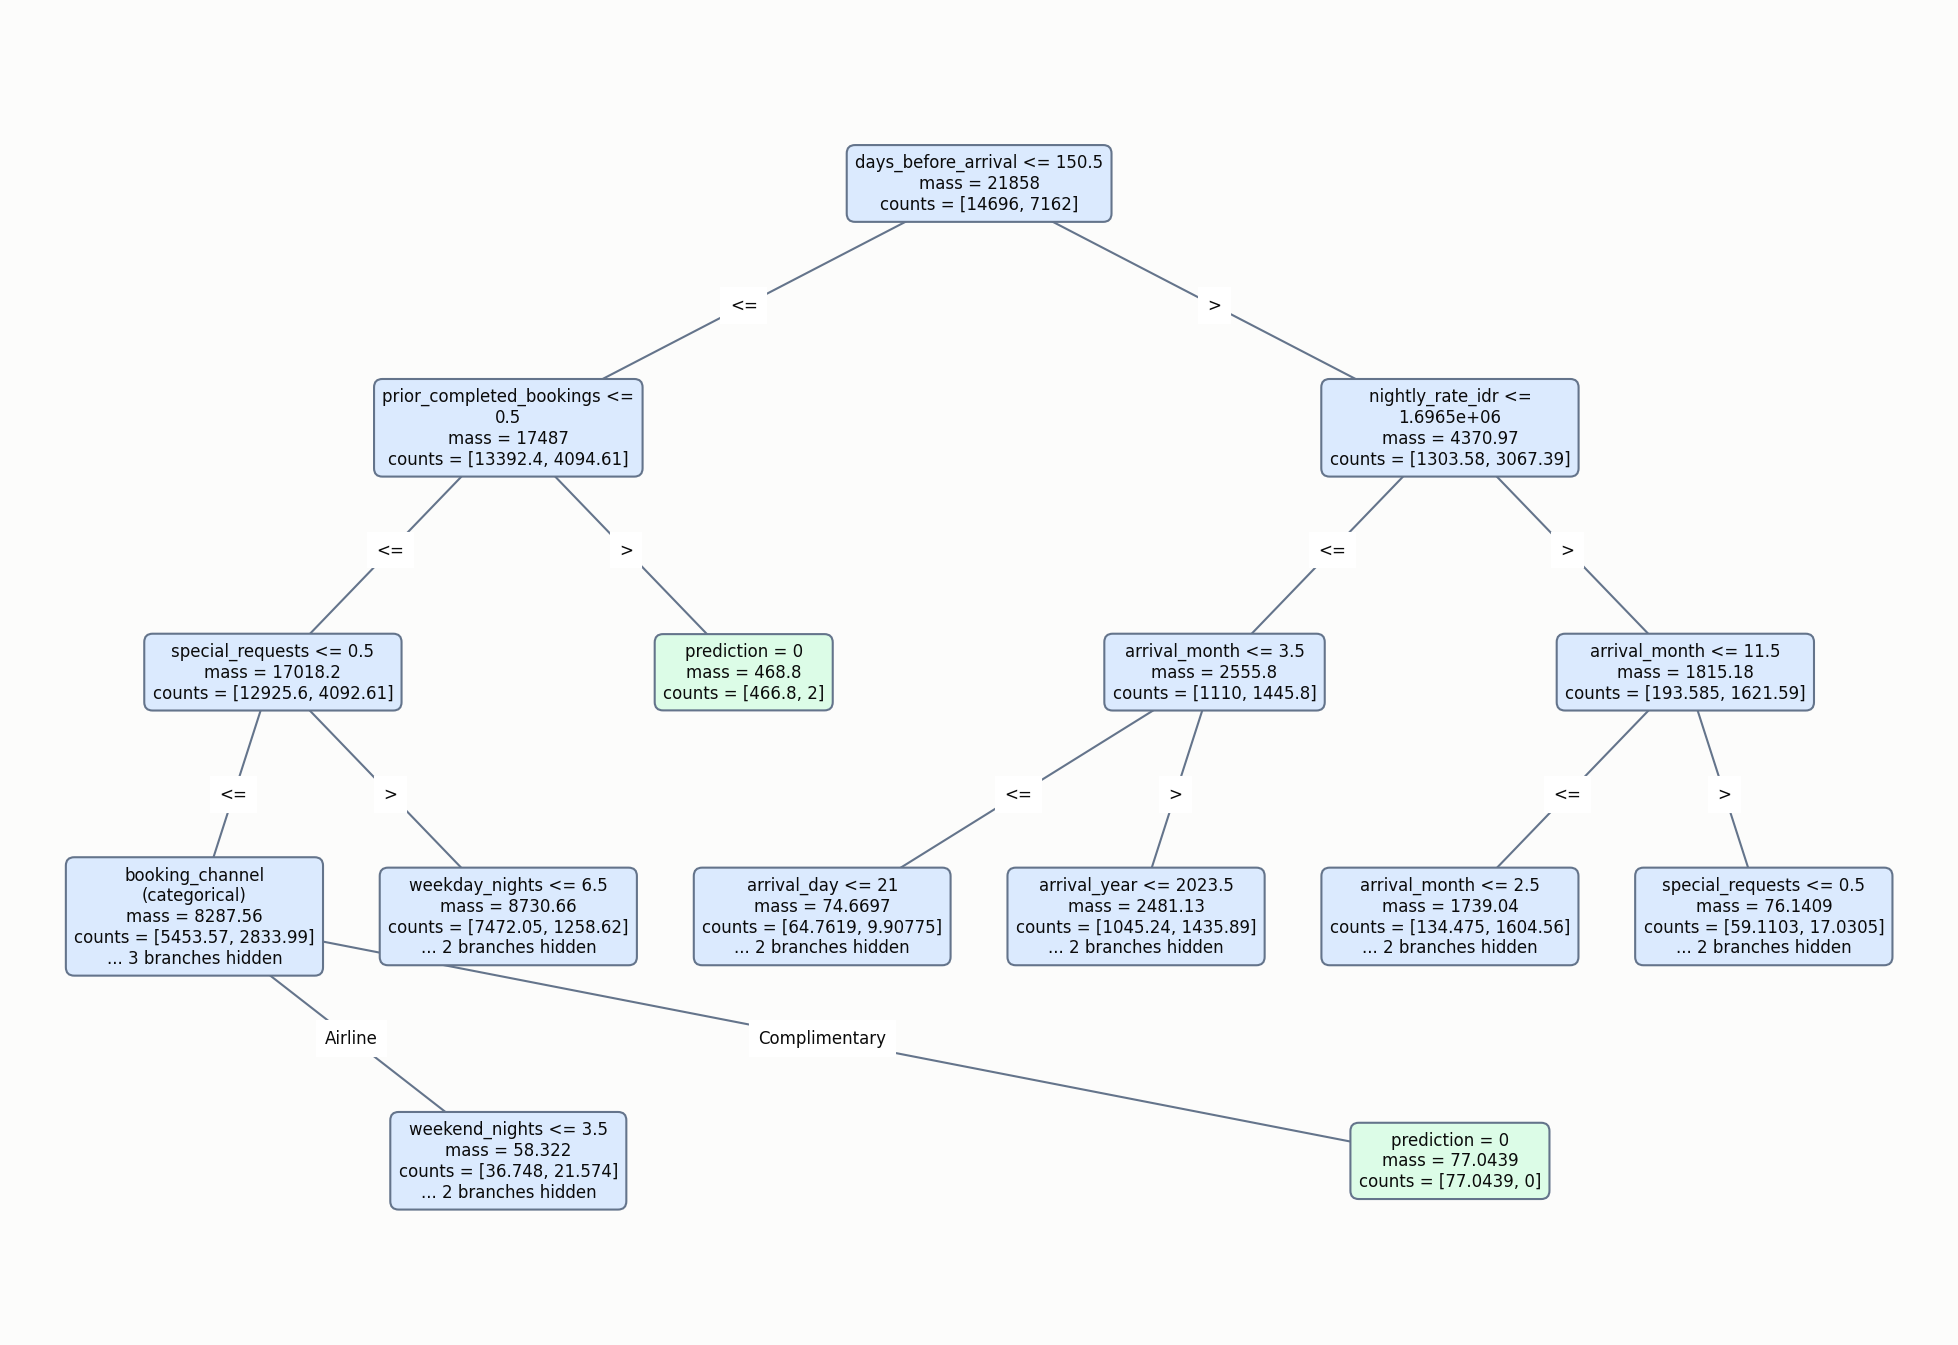

In [47]:
tree_feature_names = list(Xt_train.columns)
DT_TOP_N = 15
plot_decision_tree(dtl, config.FIGURE_DIR / "decision_tree.png", top_n=DT_TOP_N, feature_names=tree_feature_names)
dtl.export_graph(config.FIGURE_DIR / "decision_tree.dot", top_n=30, feature_names=tree_feature_names)
print("Disimpan:", (config.FIGURE_DIR / "decision_tree.png").relative_to(config.ROOT_DIR), f"(top_n={DT_TOP_N})")
print("Disimpan:", (config.FIGURE_DIR / "decision_tree.dot").relative_to(config.ROOT_DIR), "(top_n=30)")
display(Image(filename=str(config.FIGURE_DIR / "decision_tree.png")))

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [48]:
# Konfigurasi dari output/logreg_comparison/ (src.experiments.logistic_regression). logreg_tuning_cv.csv sudah terurut
# menurut macro_f1, jadi baris teratas tiap penalty dipakai untuk L1, L2, dan Elastic Net. Baris teratas keseluruhan
# (L2, reg_lambda=0.001, learning_rate=0.5, full batch, tanpa class weight) adalah konfigurasi "best" yang dipakai
# logreg_scratch_vs_sklearn_summary.csv, sehingga menjadi model Logistic Regression utama. Varian Adam terbaik dari
# adam_tuning_cv.csv ikut dievaluasi sebagai pembanding optimizer.
# Catatan: angka CSV berasal dari 5-fold pada seluruh train.csv bersih (27.309 baris), sedangkan notebook memakai
# 5-fold pada X_clean (train split), sehingga selisih kecil wajar.
LR_FIELDS = ["penalty", "reg_lambda", "l1_ratio", "learning_rate", "n_iter", "batch_size", "tol", "class_weight", "random_state"]
lr_tuning = pd.read_csv(config.OUTPUT_DIR / "logreg_comparison" / "logreg_tuning_cv.csv")
adam_tuning = pd.read_csv(config.OUTPUT_DIR / "logreg_comparison" / "adam_tuning_cv.csv")
LR_BEST = _params_from_row(lr_tuning.iloc[0], LR_FIELDS)
ADAM_BEST = _params_from_row(adam_tuning.iloc[0], [f for f in LR_FIELDS if f != "l1_ratio"])
print("Konfigurasi terbaik (gradient descent):", LR_BEST)

lr_pipeline = numeric_factory()
Xlr_train, _ = to_model_input(lr_pipeline.fit_transform(X_clean, y_clean), CATEGORICAL_COLS)
Xlr_val, _ = to_model_input(lr_pipeline.transform(X_va), CATEGORICAL_COLS)

lr_variants = {
    label: (LogisticRegression(**_params_from_row(lr_tuning[lr_tuning["penalty"] == penalty].iloc[0], LR_FIELDS)),
            lr_tuning[lr_tuning["penalty"] == penalty].iloc[0])
    for penalty, label in [("l1", "L1"), ("l2", "L2"), ("elasticnet", "Elastic Net")]
}
lr_variants["Adam (L2)"] = (AdamLogisticRegression(**ADAM_BEST), adam_tuning.iloc[0])

lr_results, rows = {}, []
for label, (model, csv_row) in lr_variants.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # peringatan konvergensi saat n_iter habis
        scores = cross_validate(model, numeric_factory, X_clean, y_clean, cv, metrics)
        fitted = model.clone().fit(Xlr_train, y_clean.to_numpy())
    pred = fitted.predict(Xlr_val)
    lr_results[label] = (scores, fitted, pred)
    rows.append(
        {
            "varian": label,
            "penalty": model.penalty,
            "reg_lambda": model.reg_lambda,
            "learning_rate": model.learning_rate,
            "cv_macro_f1": np.mean(scores["macro_f1"]),
            "cv_std": np.std(scores["macro_f1"]),
            "cv_csv": csv_row["macro_f1"],
            "cv_selisih": np.mean(scores["macro_f1"]) - csv_row["macro_f1"],
            "holdout_macro_f1": macro_f1(y_va.to_numpy(), pred),
            "bobot_nol": int(np.sum(fitted.coef_ == 0.0)),
            "konvergen": fitted.converged_,
        }
    )
lr_penalty_table = pd.DataFrame(rows).set_index("varian")

# Model Logistic Regression utama = konfigurasi "best" (baris L2).
assert lr_variants["L2"][0].get_params() == LogisticRegression(**LR_BEST).get_params()
lr_cv, lr, lr_val_pred = lr_results["L2"]
lr_val_score = lr.predict_proba(Xlr_val)[:, 1]
lr_holdout_macro_f1 = macro_f1(y_va.to_numpy(), lr_val_pred)
print(f"Model utama: L2 | Macro F1 CV {np.mean(lr_cv['macro_f1']):.4f} (std {np.std(lr_cv['macro_f1']):.4f}) | "
      f"hold-out {lr_holdout_macro_f1:.4f}")
print("Macro F1 per fold:", np.round(lr_cv["macro_f1"], 4))
print(confusion_matrix(y_va.to_numpy(), lr_val_pred))
lr_penalty_table.round(4)

Konfigurasi terbaik (gradient descent): {'penalty': 'l2', 'reg_lambda': np.float64(0.001), 'l1_ratio': np.float64(0.5), 'learning_rate': np.float64(0.5), 'n_iter': 400, 'batch_size': None, 'tol': np.float64(1e-05), 'class_weight': None, 'random_state': 42}


Model utama: L2 | Macro F1 CV 0.7611 (std 0.0053) | hold-out 0.7581
Macro F1 per fold: [0.7676 0.7631 0.7625 0.7516 0.7605]
[[3272  409]
 [ 705 1089]]


,penalty,reg_lambda,learning_rate,cv_macro_f1,cv_std,cv_csv,cv_selisih,holdout_macro_f1,bobot_nol,konvergen
varian,,,,,,,,,,
L1,l1,0.001,0.5,0.7598,0.0051,0.7588,0.0009,0.7601,15,True
L2,l2,0.001,0.5,0.7611,0.0053,0.7598,0.0012,0.7581,1,True
Elastic Net,elasticnet,0.001,0.5,0.7600,0.0053,0.7592,0.0008,0.7600,9,True
Adam (L2),l2,0.001,0.1,0.7632,0.0051,0.7620,0.0012,0.7590,1,True


### Kontur loss dan lintasan parameter (bonus)

Animasi dibuat ulang dengan `save_contour_gif` (model L2 satu fitur pada data `make_classification`): kontur
log-loss + penalti terhadap $(\theta_0, \theta_1)$ dan lintasan gradient descent dari titik nol.

Disimpan: output/figures/logreg_contour.gif


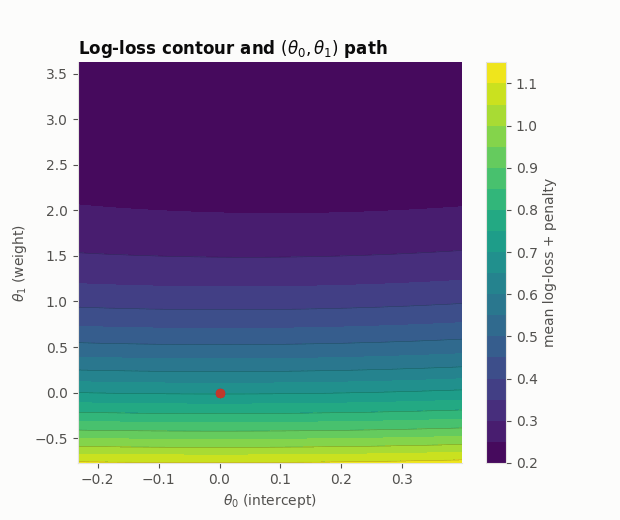

In [49]:
lr_gif_path = save_contour_gif()
print("Disimpan:", lr_gif_path.relative_to(config.ROOT_DIR))
display(Image(filename=str(lr_gif_path)))

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [50]:
# Konfigurasi terbaik dari output/svm_comparison/svm_tuning_cv.csv (baris teratas, = BEST_SVM_PARAMS di
# src.experiments.svm_experiments): kernel rbf, C=3, gamma=0.1, seluruh baris train fold, prediksi decision_function > 0.
svm = SVM(**BEST_SVM_PARAMS, random_state=SEED)
print("Parameter:", svm.get_params())
svm_cv = cross_validate(svm, numeric_factory, X_clean, y_clean, cv, metrics)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in svm_cv.items()})
print("Macro F1 per fold  :", np.round(svm_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(svm_cv['macro_f1']):.4f} (std {np.std(svm_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline numerik di-fit pada X_clean (A_tr), validasi hanya di-transform (A_va).
A_tr_arr, A_va_arr = A_tr.to_numpy(dtype=float), A_va.to_numpy(dtype=float)
svm.fit(A_tr_arr, y_clean.to_numpy())
svm_val_score = svm.decision_function(A_va_arr)
svm_val_pred = svm.predict(A_va_arr)
svm_holdout_macro_f1 = macro_f1(y_va.to_numpy(), svm_val_pred)
print(f"Macro F1 hold-out  : {svm_holdout_macro_f1:.4f} | support vector: {len(svm.support_)} | konvergen: {svm.converged_}")
print(confusion_matrix(y_va.to_numpy(), svm_val_pred))

# Kernel linear dan polynomial: konfigurasi dari svm_scratch_vs_sklearn_summary.csv, hanya dievaluasi pada hold-out.
svm_kernel_models = {
    "rbf (C=3, gamma=0.1)": svm,
    "linear (C=0.1, 5000 sampel latih)": SVM(kernel="linear", C=0.1, max_train_samples=5000, max_iter=-1, random_state=SEED),
    "poly (degree=3, C=1)": SVM(kernel="poly", C=1.0, degree=3, max_iter=-1, random_state=SEED),
}
rows = []
for name, model in svm_kernel_models.items():
    if model is not svm:
        model.fit(A_tr_arr, y_clean.to_numpy())
    rows.append(
        {
            "kernel": name,
            "n_train": min(len(A_tr_arr), model.max_train_samples or len(A_tr_arr)),
            "n_support_vector": len(model.support_),
            "holdout_macro_f1": macro_f1(y_va.to_numpy(), model.predict(A_va_arr)),
            "holdout_roc_auc": roc_auc(y_va.to_numpy(), model.decision_function(A_va_arr)),
        }
    )
svm_kernel_table = pd.DataFrame(rows).set_index("kernel")
svm_kernel_table.round(4)

Parameter: {'kernel': 'rbf', 'C': 3.0, 'degree': 3, 'gamma': 0.1, 'coef0': 1.0, 'tol': 0.001, 'max_iter': -1, 'max_train_samples': None, 'batch_size': 1024, 'class_weight': None, 'random_state': 42}


Rata-rata CV 5-fold: {'accuracy': 0.842, 'precision': 0.7911, 'recall': 0.7036, 'f1': 0.7448, 'macro_f1': 0.8152}
Macro F1 per fold  : [0.8126 0.8158 0.8192 0.8133 0.8149]
Macro F1 CV        : 0.8152 (std 0.0023)


Macro F1 hold-out  : 0.8242 | support vector: 9570 | konvergen: True
[[3373  308]
 [ 514 1280]]


,n_train,n_support_vector,holdout_macro_f1,holdout_roc_auc
kernel,,,,
"rbf (C=3, gamma=0.1)",21858,9570,0.8242,0.9009
"linear (C=0.1, 5000 sampel latih)",5000,2457,0.7562,0.8537
"poly (degree=3, C=1)",21858,9083,0.8005,0.8927


### Bidang pemisah, margin, dan support vector (bonus)

Gambar dibuat ulang dengan `plot_svm_kernels`: garis tebal adalah bidang pemisah $f(x)=0$, garis putus-putus adalah
margin $f(x)=\pm 1$, dan lingkaran hitam menandai support vector. Baris pertama memakai data sintetis 2D, baris kedua
memakai 600 sampel acak train split yang diproyeksikan ke 2 komponen PCA (PCA di-fit pada train split) dengan
`class_weight="balanced"`.

Disimpan: output/figures/svm_kernels_2d_synthetic.png


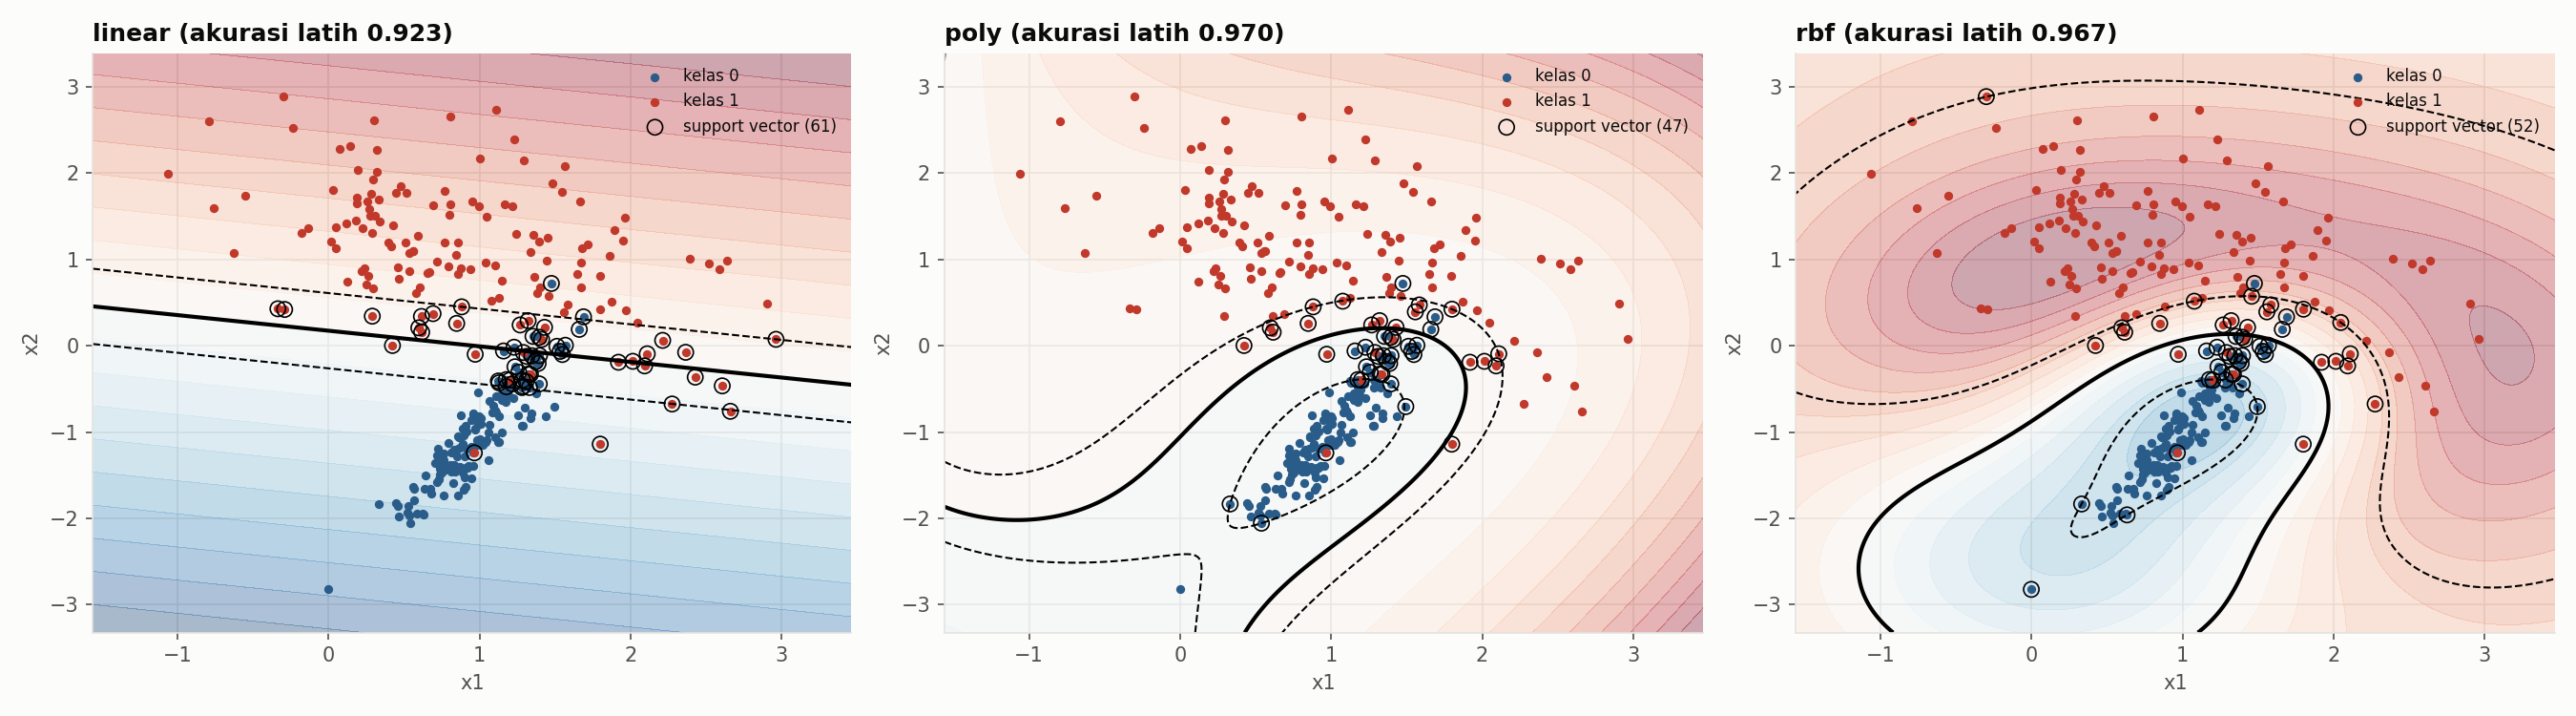

Disimpan: output/figures/svm_kernels_2d_pca.png


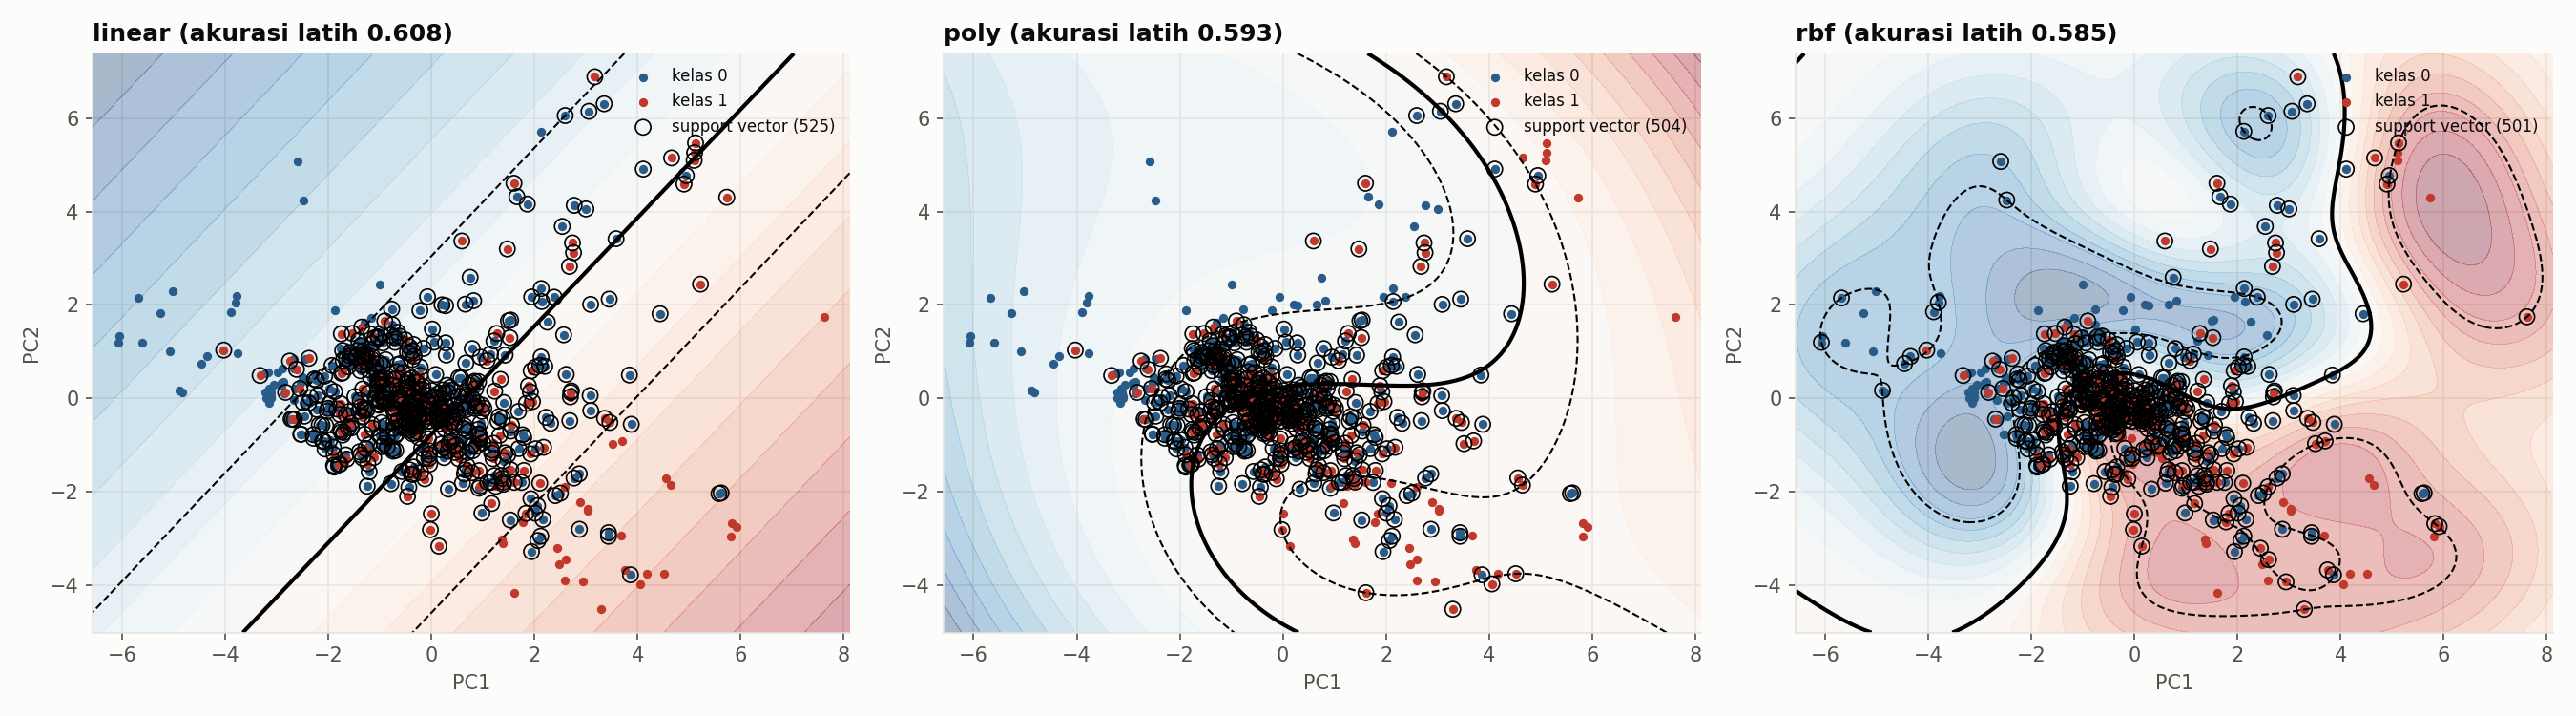

In [51]:
svm_plot_params = {"C": 1.0, "gamma": "scale", "max_iter": -1, "random_state": SEED}

X_syn, y_syn = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0,
                                   n_clusters_per_class=1, random_state=SEED)
syn_path = plot_svm_kernels(X_syn, y_syn, common_params=svm_plot_params,
                            output_path=config.FIGURE_DIR / "svm_kernels_2d_synthetic.png")

pca_2d = PCA(n_components=2).fit(A_tr)
plot_idx = np.sort(np.random.default_rng(SEED).choice(len(A_tr), size=600, replace=False))
X_pca_2d = pca_2d.transform(A_tr.iloc[plot_idx]).to_numpy()
# class_weight="balanced": pada data asli yang tumpang tindih, SVM linear tanpa bobot hampir memprediksi satu kelas saja,
# sehingga bidang pemisahnya tidak tampak di gambar.
pca_path = plot_svm_kernels(X_pca_2d, y_clean.to_numpy()[plot_idx], common_params={**svm_plot_params, "class_weight": "balanced"},
                            output_path=config.FIGURE_DIR / "svm_kernels_2d_pca.png", feature_names=("PC1", "PC2"))

for path in (syn_path, pca_path):
    print("Disimpan:", path.relative_to(config.ROOT_DIR))
    display(Image(filename=str(path)))

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [52]:
# Konfigurasi terbaik dari output/knn_naivebayes_comparison.csv (baris Naive Bayes from-scratch):
# alpha=0.5, var_smoothing=1e-12, pipeline tree, RandomOverSampler(sampling_strategy=0.75, seed 42)
# hanya pada data train, threshold 0.5 (= argmax, tanpa ThresholdedModel).
NB_ALPHA, NB_VAR_SMOOTHING, NB_THRESHOLD, NB_OVER_STRATEGY = 0.5, 1e-12, 0.5, 0.75
nb_resampler = RandomOverSampler(sampling_strategy=NB_OVER_STRATEGY, random_state=SEED)

nb = NaiveBayes(categorical_features=tree_cat_idx, alpha=NB_ALPHA, var_smoothing=NB_VAR_SMOOTHING)
nb_model = with_threshold(nb, NB_THRESHOLD)
print("Parameter:", nb.get_params(), "| threshold:", NB_THRESHOLD)

nb_cv = cross_validate(nb_model, tree_factory, X_clean, y_clean, cv, metrics, resampler=nb_resampler)
print("Rata-rata CV 5-fold:", {k: round(float(np.mean(v)), 4) for k, v in nb_cv.items()})
print("Macro F1 per fold  :", np.round(nb_cv["macro_f1"], 4))
print(f"Macro F1 CV        : {np.mean(nb_cv['macro_f1']):.4f} (std {np.std(nb_cv['macro_f1']):.4f})")

# Hold-out 20%: pipeline tree di-fit pada X_clean, oversampling hanya pada data train.
Xnb_val, _ = to_model_input(tree_pipeline.transform(X_va), CATEGORICAL_COLS)
Xnb_res, ynb_res = nb_resampler.fit_resample(Xt_input, y_clean.to_numpy())
print(f"Train sebelum/sesudah oversampling: {len(Xt_input)} -> {len(Xnb_res)} baris | kelas 1: {int(ynb_res.sum())}")
nb.fit(Xnb_res, ynb_res)
nb_val_score = nb.predict_proba(Xnb_val)[:, 1]
nb_val_pred = nb_model.predict(Xnb_val)
nb_holdout_macro_f1 = macro_f1(y_va.to_numpy(), nb_val_pred)
print(f"Macro F1 hold-out  : {nb_holdout_macro_f1:.4f}")
print(confusion_matrix(y_va.to_numpy(), nb_val_pred))

Parameter: {'categorical_features': [21, 22, 23], 'alpha': 0.5, 'var_smoothing': 1e-12, 'random_state': 42} | threshold: 0.5


Rata-rata CV 5-fold: {'accuracy': 0.739, 'precision': 0.613, 'recall': 0.5518, 'f1': 0.5807, 'macro_f1': 0.6956}
Macro F1 per fold  : [0.7016 0.6944 0.6978 0.6864 0.698 ]
Macro F1 CV        : 0.6956 (std 0.0052)
Train sebelum/sesudah oversampling: 21858 -> 25718 baris | kelas 1: 11022
Macro F1 hold-out  : 0.6998
[[3040  641]
 [ 778 1016]]


### Graf Naive Bayes (bonus)

Graf independensi bersyarat: node kelas `is_canceled` menjadi induk setiap fitur input pipeline tree
(biru: numerik, kuning: kategorik).

Disimpan: output/figures/naive_bayes_graph.png


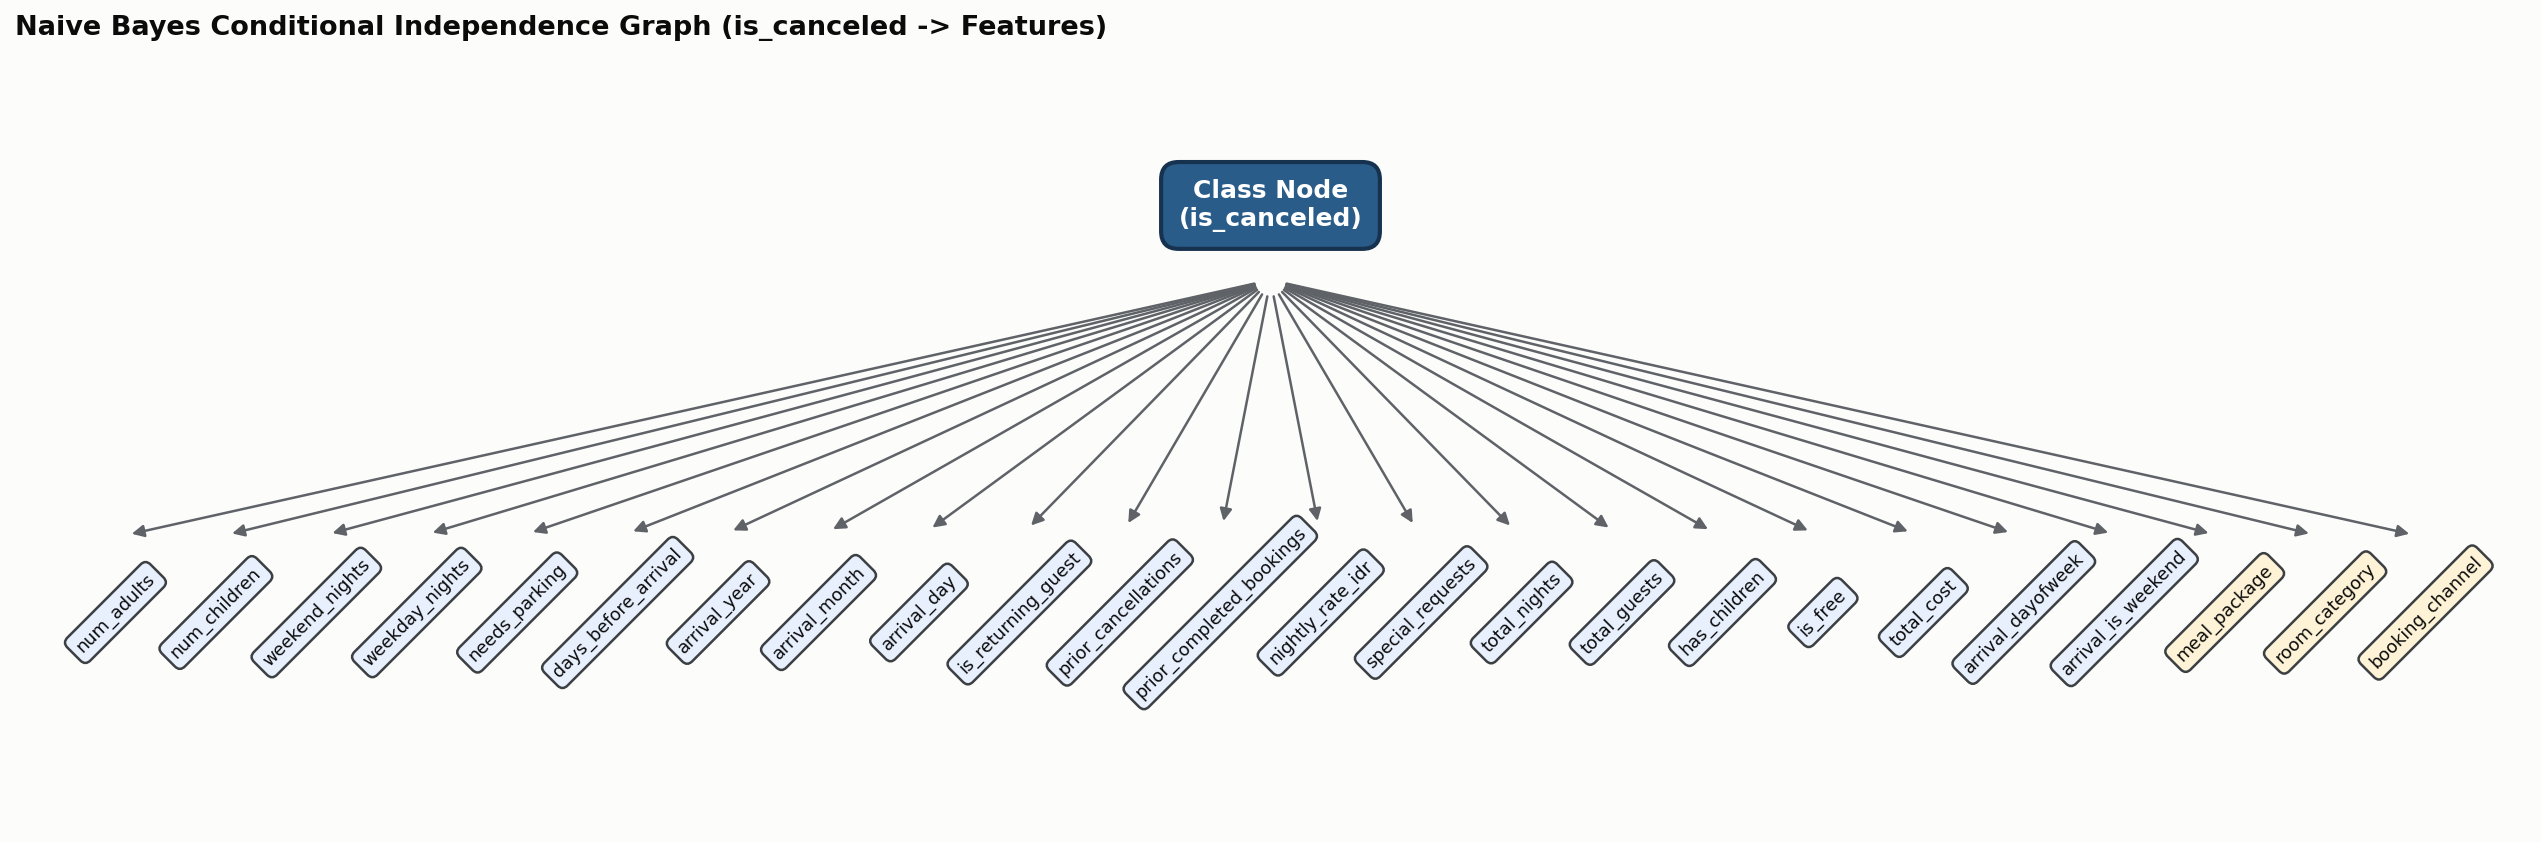

In [53]:
nb_graph_path = plot_naive_bayes_graph(feature_names=list(Xt_train.columns),
                                       output_path=config.FIGURE_DIR / "naive_bayes_graph.png")
print("Disimpan:", nb_graph_path.relative_to(config.ROOT_DIR))
display(Image(filename=str(nb_graph_path)))

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [54]:
# Demonstrasi grid_search dengan grid kecil: ruang parameter yang sama dengan tuning Decision Tree
# (GRID_PARAM_SPACE di src.experiments.decision_tree), 3-fold StratifiedKFold pada train split, scoring macro_f1.
grid_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
grid_base = DecisionTree(categorical_features=tree_cat_idx, random_state=SEED, **DT_DEFAULT_PARAMS)
best_params, search_log = grid_search(grid_base, GRID_PARAM_SPACE, tree_factory, X_clean, y_clean, grid_cv, scoring=macro_f1)

grid_table = pd.DataFrame(
    [{**r["params"], "mean_macro_f1": r["mean_score"], "std_macro_f1": np.std(r["scores"])} for r in search_log]
).sort_values("mean_macro_f1", ascending=False, ignore_index=True)
print("Grid:", GRID_PARAM_SPACE)
print("Parameter terbaik:", best_params)
print("Sama dengan konfigurasi tuned:", all(DT_TUNED_PARAMS[k] == v for k, v in best_params.items()))
grid_table.round(4)

Grid: {'max_depth': [8, 12], 'min_samples_leaf': [5, 10]}
Parameter terbaik: {'max_depth': 12, 'min_samples_leaf': 5}
Sama dengan konfigurasi tuned: True


,max_depth,min_samples_leaf,mean_macro_f1,std_macro_f1
0,12,5,0.8100,0.0034
1,12,10,0.8067,0.0009
2,8,5,0.7952,0.0045
3,8,10,0.7949,0.0039


### Cost-Sensitive Learning

Dengan biaya FP = 2 dan FN = 1, threshold optimal Bayes adalah `FP / (FP + FN)` = 2/3: model baru
memprediksi batal jika peluang batal melebihi 2/3. Demonstrasi di bawah memakai skor Logistic Regression scikit-learn.

Cost pada threshold 0.5     : 1515
Cost pada threshold Bayes   : 1380 (t = 0.667)
Cost minimum hasil sweep    : 1375 (t = 0.66)


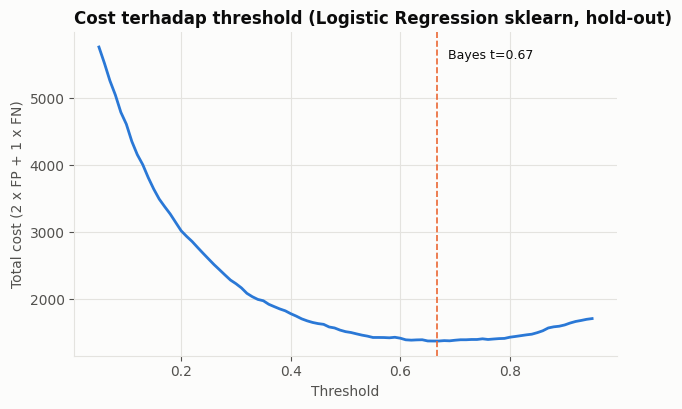

Disimpan: output/figures/cost_threshold_sweep.png


In [55]:
y_true_va = y_va.to_numpy()
cost_lr = SkLogisticRegression(max_iter=1000, random_state=SEED).fit(A_tr, y_tr)
proba = cost_lr.predict_proba(A_va)[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)


def cost_at(threshold):
    pred = (proba >= threshold).astype(int)
    fp = int(((pred == 1) & (y_true_va == 0)).sum())
    fn = int(((pred == 0) & (y_true_va == 1)).sum())
    return config.FP_COST * fp + config.FN_COST * fn


costs = np.array([cost_at(t) for t in thresholds])
best_t = thresholds[int(np.argmin(costs))]
bayes_t = config.FP_COST / (config.FP_COST + config.FN_COST)
print(f"Cost pada threshold 0.5     : {cost_at(0.5):.0f}")
print(f"Cost pada threshold Bayes   : {cost_at(bayes_t):.0f} (t = {bayes_t:.3f})")
print(f"Cost minimum hasil sweep    : {costs.min():.0f} (t = {best_t:.2f})")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(thresholds, costs, color=BLUE)
ax.axvline(bayes_t, color=ORANGE, linewidth=1.2, linestyle="--")
ax.annotate(f"Bayes t={bayes_t:.2f}", (bayes_t, costs.max()), xytext=(bayes_t + 0.02, costs.max() * 0.97), fontsize=9)
ax.set_xlabel("Threshold")
ax.set_ylabel("Total cost (2 x FP + 1 x FN)")
ax.set_title("Cost terhadap threshold (Logistic Regression sklearn, hold-out)")
save_fig(fig, "cost_threshold_sweep")

#### Cost-sensitive pada model terbaik dengan `predict_proba` (Decision Tree tuned)

`src.evaluation.cost_sensitive` dipakai untuk threshold Bayes, threshold hasil `tune_threshold`, dan bobot kelas.
Threshold cost dipilih dari probabilitas out-of-fold 5-fold pada train split, lalu diuji pada `val_set`.
"Sebelum" adalah threshold Macro F1 model (0.33), "sesudah" adalah threshold hasil `tune_threshold`.

In [56]:
FP_COST, FN_COST = config.FP_COST, config.FN_COST
bayes_t = bayes_optimal_threshold(FP_COST, FN_COST)
cost_class_weight = cost_sensitive_class_weight(FP_COST, FN_COST)
print(f"FP_COST={FP_COST}, FN_COST={FN_COST} | threshold Bayes: {bayes_t:.4f} | class weight: {cost_class_weight}")

dt_oof_proba = find_oof_threshold(dtl, tree_factory, X_clean, y_clean, cv)["oof_proba"]
cost_t = tune_threshold(y_clean.to_numpy(), dt_oof_proba, FP_COST, FN_COST)
y_true_va = y_va.to_numpy()


def cost_row(rule, threshold, scores):
    pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_true_va, pred)
    return {"aturan": rule, "threshold": threshold, "FP": int(cm[0, 1]), "FN": int(cm[1, 0]),
            "cost": misclassification_cost(y_true_va, pred, FP_COST, FN_COST), "macro_f1": macro_f1(y_true_va, pred)}


cost_table = pd.DataFrame(
    [
        cost_row("argmax (0.5)", 0.5, dtl_val_score),
        cost_row("threshold Macro F1 (sebelum)", DT_THRESHOLD, dtl_val_score),
        cost_row("threshold Bayes FP/(FP+FN)", bayes_t, dtl_val_score),
        cost_row("tune_threshold OOF (sesudah)", cost_t, dtl_val_score),
    ]
).set_index("aturan")
cost_before = cost_table.loc["threshold Macro F1 (sebelum)", "cost"]
cost_after = cost_table.loc["tune_threshold OOF (sesudah)", "cost"]
print(f"Decision Tree tuned, val_set: cost sebelum {cost_before:.0f} -> sesudah {cost_after:.0f} "
      f"({cost_after - cost_before:+.0f}, threshold {DT_THRESHOLD} -> {cost_t:.4f})")

# DecisionTree tidak menerima bobot kelas, jadi cost_sensitive_class_weight didemonstrasikan pada Logistic Regression sendiri.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    lr_cost = LogisticRegression(**{**LR_BEST, "class_weight": cost_class_weight}).fit(Xlr_train, y_clean.to_numpy())
lr_cost_pred = lr_cost.predict(Xlr_val)
print(f"Logistic Regression L2, val_set: cost tanpa bobot {misclassification_cost(y_true_va, lr_val_pred):.0f} -> "
      f"dengan class_weight {misclassification_cost(y_true_va, lr_cost_pred):.0f} "
      f"(Macro F1 {lr_holdout_macro_f1:.4f} -> {macro_f1(y_true_va, lr_cost_pred):.4f})")
cost_table.round(4)

FP_COST=2.0, FN_COST=1.0 | threshold Bayes: 0.6667 | class weight: {0: 2.0, 1: 1.0}


Decision Tree tuned, val_set: cost sebelum 1266 -> sesudah 1106 (-160, threshold 0.33 -> 0.6701)
Logistic Regression L2, val_set: cost tanpa bobot 1523 -> dengan class_weight 1372 (Macro F1 0.7581 -> 0.7041)


,threshold,FP,FN,cost,macro_f1
aturan,,,,,
argmax (0.5),0.5000,320,528,1168.0,0.8185
threshold Macro F1 (sebelum),0.3300,429,408,1266.0,0.8270
threshold Bayes FP/(FP+FN),0.6667,202,697,1101.0,0.7975
tune_threshold OOF (sesudah),0.6701,199,708,1106.0,0.7951


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

Tabel dan grafik di bawah membandingkan Macro F1 (metrik Kaggle) kelima model, versi sendiri dan scikit-learn:
rata-rata 5-fold `StratifiedKFold` pada train split (`cross_validate`) dan skor hold-out pada `val_set`. Sel pertama
menjalankan versi scikit-learn dengan protokol yang sama; rincian per model ditampilkan di bagian Comparison with
scikit-learn. Decision Tree ditampilkan dalam konfigurasi tuned dan default.

In [57]:
# Versi scikit-learn kelima model: cross_validate 5-fold yang sama dan hold-out val_set.
def sk_evaluate(y_true, y_pred, y_score=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": sk_f1(y_true, y_pred),
        "macro_f1": macro_f1(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "cost": config.FP_COST * fp + config.FN_COST * fn,
    }


class SagaLogisticRegression:
    # Padanan sklearn (solver saga) untuk konfigurasi Logistic Regression sendiri. C = 1 / (reg_lambda * n_train)
    # dihitung dari ukuran data saat fit, sama dengan _sklearn_model di src.experiments.logistic_regression.
    def __init__(self, params):
        self.params = params

    def clone(self):
        return SagaLogisticRegression(self.params)

    def fit(self, X, y):
        self.model_ = _sklearn_model(self.params, len(y)).fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


sk_results, sk_scores = {}, {}

# KNN: konfigurasi sama dengan KNN sendiri (k=15, distance, pipeline numerik + PCA 95%, threshold 0.45).
sk_knn = KNeighborsClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
sk_knn_model = with_threshold(sk_knn, KNN_THRESHOLD)
sk_knn_cv = cross_validate(sk_knn_model, knn_factory, X_clean, y_clean, cv, metrics)
sk_knn.fit(Xk_train, y_clean.to_numpy())
sk_scores["KNN"] = sk_knn.predict_proba(Xk_val)[:, 1]
sk_results["KNN"] = sk_evaluate(y_va, sk_knn_model.predict(Xk_val), sk_scores["KNN"])

# Decision Tree: baris scikit-learn di dtl_tuning_comparison.csv (entropy, ccp_alpha=0, pipeline numerik).
SK_DT_DEFAULT = {"criterion": "entropy", "ccp_alpha": 0.0, "max_depth": None, "min_samples_split": 2,
                 "min_samples_leaf": 1, "random_state": SEED}
SK_DT_TUNED = {**SK_DT_DEFAULT, "max_depth": 12, "min_samples_leaf": 5}
sk_dt_default = DecisionTreeClassifier(**SK_DT_DEFAULT).fit(A_tr, y_tr)
sk_dt_default_cv = cross_validate(DecisionTreeClassifier(**SK_DT_DEFAULT), numeric_factory, X_clean, y_clean, cv, metrics)
sk_scores["DTL (default)"] = sk_dt_default.predict_proba(A_va)[:, 1]
sk_results["DTL (default)"] = sk_evaluate(y_va, sk_dt_default.predict(A_va), sk_scores["DTL (default)"])
sk_dt = DecisionTreeClassifier(**SK_DT_TUNED).fit(A_tr, y_tr)
sk_dt_cv = cross_validate(DecisionTreeClassifier(**SK_DT_TUNED), numeric_factory, X_clean, y_clean, cv, metrics)
sk_scores["DTL"] = sk_dt.predict_proba(A_va)[:, 1]
sk_results["DTL"] = sk_evaluate(y_va, sk_dt.predict(A_va), sk_scores["DTL"])

# Logistic Regression: saga dengan penalti yang setara konfigurasi LR_BEST.
sk_lr_cv = cross_validate(SagaLogisticRegression(LR_BEST), numeric_factory, X_clean, y_clean, cv, metrics)
sk_lr = SagaLogisticRegression(LR_BEST).fit(Xlr_train, y_clean.to_numpy())
sk_scores["Logistic Regression"] = sk_lr.predict_proba(Xlr_val)[:, 1]
sk_results["Logistic Regression"] = sk_evaluate(y_va, sk_lr.predict(Xlr_val), sk_scores["Logistic Regression"])

# SVM: SVC(kernel="rbf", C=3, gamma=0.1), padanan di svm_team_cv_comparison.csv.
sk_svm = SVC(kernel="rbf", C=BEST_SVM_PARAMS["C"], gamma=BEST_SVM_PARAMS["gamma"])
sk_svm_cv = cross_validate(sk_svm, numeric_factory, X_clean, y_clean, cv, metrics)
sk_svm.fit(A_tr_arr, y_clean.to_numpy())
sk_scores["SVM"] = sk_svm.decision_function(A_va_arr)
sk_results["SVM"] = sk_evaluate(y_va, sk_svm.predict(A_va_arr), sk_scores["SVM"])

# Naive Bayes: GaussianNB(var_smoothing=1e-6), pipeline numerik. Threshold dicari dengan find_oof_threshold
# (5-fold OOF pada X_clean, bukan val_set); CV di bawah sedikit optimistis karena memakai fold yang sama.
SK_NB_VAR_SMOOTHING = 1e-6
sk_nb = GaussianNB(var_smoothing=SK_NB_VAR_SMOOTHING)
sk_nb_search = find_oof_threshold(sk_nb, numeric_factory, X_clean, y_clean, cv)
SK_NB_THRESHOLD = sk_nb_search["threshold"]
sk_nb_model = with_threshold(sk_nb, SK_NB_THRESHOLD)
sk_nb_cv = cross_validate(sk_nb_model, numeric_factory, X_clean, y_clean, cv, metrics)
sk_nb.fit(A_tr, y_tr)
sk_scores["Naive Bayes"] = sk_nb.predict_proba(A_va)[:, 1]
sk_results["Naive Bayes"] = sk_evaluate(y_va, sk_nb_model.predict(A_va), sk_scores["Naive Bayes"])

for name, scores in [("KNN", sk_knn_cv), ("DTL (default)", sk_dt_default_cv), ("DTL", sk_dt_cv),
                     ("Logistic Regression", sk_lr_cv), ("SVM", sk_svm_cv), ("Naive Bayes", sk_nb_cv)]:
    print(f"scikit-learn {name:<20}: Macro F1 CV {np.mean(scores['macro_f1']):.4f} | hold-out {sk_results[name]['macro_f1']:.4f}")

scikit-learn KNN                 : Macro F1 CV 0.8124 | hold-out 0.8216
scikit-learn DTL (default)       : Macro F1 CV 0.8025 | hold-out 0.8127
scikit-learn DTL                 : Macro F1 CV 0.8226 | hold-out 0.8238
scikit-learn Logistic Regression : Macro F1 CV 0.7631 | hold-out 0.7594
scikit-learn SVM                 : Macro F1 CV 0.8152 | hold-out 0.8242
scikit-learn Naive Bayes         : Macro F1 CV 0.6864 | hold-out 0.6872


In [58]:
eval_rows = []


def add_eval_row(model, implementation, cv_macro_f1, holdout_macro_f1):
    """Satu baris tabel evaluasi: Macro F1 CV (mean, std) dan hold-out."""
    eval_rows.append(
        {
            "model": model,
            "implementasi": implementation,
            "cv_macro_f1_mean": float(np.mean(cv_macro_f1)),
            "cv_macro_f1_std": float(np.std(cv_macro_f1)),
            "holdout_macro_f1": float(holdout_macro_f1),
        }
    )


add_eval_row("KNN", "sendiri", knn_cv["macro_f1"], knn_holdout_macro_f1)
add_eval_row("KNN", "scikit-learn", sk_knn_cv["macro_f1"], sk_results["KNN"]["macro_f1"])
add_eval_row("Naive Bayes", "sendiri", nb_cv["macro_f1"], nb_holdout_macro_f1)
add_eval_row("Naive Bayes", "scikit-learn", sk_nb_cv["macro_f1"], sk_results["Naive Bayes"]["macro_f1"])
add_eval_row("Decision Tree (tuned)", "sendiri", dtl_cv["macro_f1"], dtl_holdout_macro_f1)
add_eval_row("Decision Tree (tuned)", "scikit-learn", sk_dt_cv["macro_f1"], sk_results["DTL"]["macro_f1"])
add_eval_row("Decision Tree (default)", "sendiri", dtl_default_cv["macro_f1"], dtl_default_holdout_macro_f1)
add_eval_row("Decision Tree (default)", "scikit-learn", sk_dt_default_cv["macro_f1"], sk_results["DTL (default)"]["macro_f1"])
add_eval_row("Logistic Regression", "sendiri", lr_cv["macro_f1"], lr_holdout_macro_f1)
add_eval_row("Logistic Regression", "scikit-learn", sk_lr_cv["macro_f1"], sk_results["Logistic Regression"]["macro_f1"])
add_eval_row("SVM", "sendiri", svm_cv["macro_f1"], svm_holdout_macro_f1)
add_eval_row("SVM", "scikit-learn", sk_svm_cv["macro_f1"], sk_results["SVM"]["macro_f1"])

evaluation_table = pd.DataFrame(eval_rows).set_index(["model", "implementasi"])
evaluation_table.round(4)

cv_macro_f1_mean  cv_macro_f1_std  holdout_macro_f1
model                   implementasi                                                     
KNN                     sendiri                 0.8124           0.0024            0.8216
                        scikit-learn            0.8124           0.0024            0.8216
Naive Bayes             sendiri                 0.6956           0.0052            0.6998
                        scikit-learn            0.6864           0.0092            0.6872
Decision Tree (tuned)   sendiri                 0.8225           0.0044            0.8270
                        scikit-learn            0.8226           0.0062            0.8238
Decision Tree (default) sendiri                 0.8201           0.0045            0.8261
                        scikit-learn            0.8025           0.0093            0.8127
Logistic Regression     sendiri                 0.7611           0.0053            0.7581
                        scikit-learn            0.7631           0.0049            0.7594
SVM                     sendiri                 0.8152           0.0023            0.8242
                        scikit-learn            0.8152           0.0023            0.8242

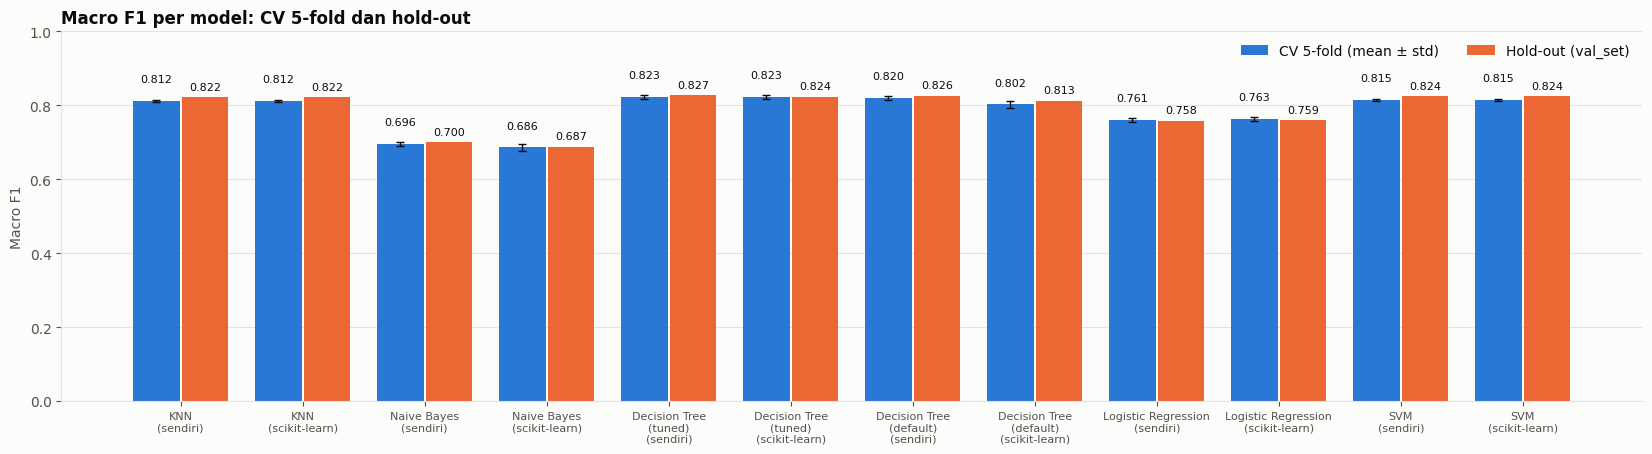

Disimpan: output/figures/model_evaluation_macro_f1.png


In [59]:
labels = [f"{m.replace(' (', chr(10) + '(')}\n({i})" for m, i in evaluation_table.index]
pos = np.arange(len(evaluation_table))

fig, ax = plt.subplots(figsize=(max(8, 1.7 * len(pos)), 4.8))
cv_bars = ax.bar(pos - 0.2, evaluation_table["cv_macro_f1_mean"], width=0.38, color=BLUE,
                 yerr=evaluation_table["cv_macro_f1_std"], error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3},
                 label="CV 5-fold (mean ± std)")
ho_bars = ax.bar(pos + 0.2, evaluation_table["holdout_macro_f1"], width=0.38, color=ORANGE, label="Hold-out (val_set)")
for bars in (cv_bars, ho_bars):
    for bar in bars:
        ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4 if bars is ho_bars else 12), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color=INK)
ax.set_xticks(pos, labels, fontsize=8)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 per model: CV 5-fold dan hold-out")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=2)
save_fig(fig, "model_evaluation_macro_f1")

### Konsistensi dengan `output/knn_naivebayes_comparison.csv`

Selisih threshold, Macro F1 CV, dan Macro F1 hold-out notebook terhadap CSV (notebook − CSV) untuk setiap baris KNN dan
Naive Bayes. Angka tidak disesuaikan; selisih Macro F1 di atas 0.005 hanya ditandai.

In [60]:
reference = pd.read_csv(config.OUTPUT_DIR / "knn_naivebayes_comparison.csv")
impl_map = {"from-scratch": "sendiri", "scikit-learn": "scikit-learn"}
reference["implementasi"] = reference["implementation"].map(impl_map)
reference = reference.set_index(["model", "implementasi"])

notebook_thresholds = {
    ("KNN", "sendiri"): KNN_THRESHOLD,
    ("KNN", "scikit-learn"): KNN_THRESHOLD,
    ("Naive Bayes", "sendiri"): NB_THRESHOLD,
    ("Naive Bayes", "scikit-learn"): SK_NB_THRESHOLD,
}

rows = []
for key in reference.index:
    nb_row, ref = evaluation_table.loc[key], reference.loc[key]
    rows.append(
        {
            "model": key[0],
            "implementasi": key[1],
            "threshold_notebook": notebook_thresholds[key],
            "threshold_csv": ref["threshold"],
            "threshold_selisih": notebook_thresholds[key] - ref["threshold"],
            "cv_notebook": nb_row["cv_macro_f1_mean"],
            "cv_csv": ref["cv_mean_macro_f1"],
            "cv_selisih": nb_row["cv_macro_f1_mean"] - ref["cv_mean_macro_f1"],
            "holdout_notebook": nb_row["holdout_macro_f1"],
            "holdout_csv": ref["holdout_macro_f1"],
            "holdout_selisih": nb_row["holdout_macro_f1"] - ref["holdout_macro_f1"],
        }
    )
check = pd.DataFrame(rows).set_index(["model", "implementasi"])
check["lebih_dari_0.005"] = (check[["cv_selisih", "holdout_selisih"]].abs() > 0.005).any(axis=1)

for (model, impl), row in check.iterrows():
    print(
        f"{model} ({impl}): threshold {row['threshold_selisih']:+.3e} | "
        f"CV {row['cv_selisih']:+.4f} | hold-out {row['holdout_selisih']:+.4f}"
        + ("  <- lebih dari 0.005" if row["lebih_dari_0.005"] else "")
    )

formats = {"threshold_notebook": "{:.10g}", "threshold_csv": "{:.10g}", "threshold_selisih": "{:+.3e}",
           "cv_selisih": "{:+.4f}", "holdout_selisih": "{:+.4f}",
           "cv_notebook": "{:.4f}", "cv_csv": "{:.4f}", "holdout_notebook": "{:.4f}", "holdout_csv": "{:.4f}"}
check_display = check.copy()
for col, fmt in formats.items():
    check_display[col] = check[col].map(fmt.format)
check_display

KNN (sendiri): threshold +0.000e+00 | CV -0.0035 | hold-out +0.0000
KNN (scikit-learn): threshold +0.000e+00 | CV -0.0035 | hold-out +0.0000
Naive Bayes (sendiri): threshold +0.000e+00 | CV -0.0005 | hold-out +0.0000
Naive Bayes (scikit-learn): threshold -1.027e-07 | CV +0.0123 | hold-out +0.0024  <- lebih dari 0.005


threshold_notebook threshold_csv threshold_selisih cv_notebook  cv_csv cv_selisih holdout_notebook holdout_csv  \
model       implementasi                                                                                                                  
KNN         sendiri                    0.45          0.45        +0.000e+00      0.8124  0.8159    -0.0035           0.8216      0.8216   
            scikit-learn               0.45          0.45        +0.000e+00      0.8124  0.8159    -0.0035           0.8216      0.8216   
Naive Bayes sendiri                     0.5           0.5        +0.000e+00      0.6956  0.6962    -0.0005           0.6998      0.6998   
            scikit-learn       0.9999990058  0.9999991084        -1.027e-07      0.6864  0.6741    +0.0123           0.6872      0.6848   

                         holdout_selisih  lebih_dari_0.005  
model       implementasi                                    
KNN         sendiri              +0.0000             False  
            scikit-learn         +0.0000             False  
Naive Bayes sendiri              +0.0000             False  
            scikit-learn         +0.0024              True

### Konsistensi dengan CSV Decision Tree, Logistic Regression, dan SVM

Selisih Macro F1 notebook terhadap CSV eksperimen (notebook − CSV), tanpa penyesuaian angka.
`dtl_tuning_comparison.csv` memakai protokol yang sama dengan notebook (split 80/20 seed 42, 5-fold pada train split,
hold-out `val_set`). `logreg_scratch_vs_sklearn_summary.csv` dan `svm_team_cv_comparison.csv` memakai 5-fold pada
seluruh `train.csv` bersih tanpa hold-out, sehingga hanya CV yang dibandingkan dan selisih kecil wajar.

In [61]:
csv_rows = []
for _, r in pd.read_csv(config.OUTPUT_DIR / "dtl_tuning_comparison.csv").iterrows():
    csv_rows.append({"model": r["model"], "implementasi": impl_map[r["implementation"]], "sumber": "dtl_tuning_comparison.csv",
                     "cv_csv": r["cv_mean_macro_f1"], "holdout_csv": r["holdout_macro_f1"]})
for _, r in pd.read_csv(config.OUTPUT_DIR / "logreg_comparison" / "logreg_scratch_vs_sklearn_summary.csv").iterrows():
    csv_rows.append({"model": "Logistic Regression", "implementasi": {"scratch": "sendiri", "sklearn": "scikit-learn"}[r["impl"]],
                     "sumber": "logreg_scratch_vs_sklearn_summary.csv", "cv_csv": r["macro_f1"], "holdout_csv": np.nan})
svm_team = pd.read_csv(config.OUTPUT_DIR / "svm_comparison" / "svm_team_cv_comparison.csv")
for _, r in svm_team[svm_team["config"] == "rbf_best_C3_g0.1"].iterrows():
    csv_rows.append({"model": "SVM", "implementasi": {"scratch": "sendiri", "sklearn": "scikit-learn"}[r["impl"]],
                     "sumber": "svm_team_cv_comparison.csv", "cv_csv": r["macro_f1"], "holdout_csv": np.nan})

csv_check = pd.DataFrame(csv_rows).set_index(["model", "implementasi"])
csv_check["cv_notebook"] = [evaluation_table.loc[key, "cv_macro_f1_mean"] for key in csv_check.index]
csv_check["cv_selisih"] = csv_check["cv_notebook"] - csv_check["cv_csv"]
csv_check["holdout_notebook"] = [evaluation_table.loc[key, "holdout_macro_f1"] for key in csv_check.index]
csv_check["holdout_selisih"] = csv_check["holdout_notebook"] - csv_check["holdout_csv"]
csv_check = csv_check[["sumber", "cv_notebook", "cv_csv", "cv_selisih", "holdout_notebook", "holdout_csv", "holdout_selisih"]]

for (model, impl), row in csv_check.iterrows():
    holdout = "tidak ada di CSV" if np.isnan(row["holdout_csv"]) else f"{row['holdout_selisih']:+.4f}"
    print(f"{model} ({impl}): CV {row['cv_selisih']:+.4f} | hold-out {holdout}")
csv_check.round(4)

Decision Tree (default) (sendiri): CV +0.0000 | hold-out +0.0000


Decision Tree (tuned) (sendiri): CV +0.0000 | hold-out +0.0000
Decision Tree (default) (scikit-learn): CV -0.0005 | hold-out +0.0019
Decision Tree (tuned) (scikit-learn): CV +0.0000 | hold-out -0.0002
Logistic Regression (sendiri): CV +0.0013 | hold-out tidak ada di CSV
Logistic Regression (scikit-learn): CV +0.0021 | hold-out tidak ada di CSV
SVM (sendiri): CV -0.0057 | hold-out tidak ada di CSV
SVM (scikit-learn): CV -0.0057 | hold-out tidak ada di CSV


sumber  cv_notebook  cv_csv  cv_selisih  holdout_notebook  \
model                   implementasi                                                                                             
Decision Tree (default) sendiri                   dtl_tuning_comparison.csv       0.8201  0.8201      0.0000            0.8261   
Decision Tree (tuned)   sendiri                   dtl_tuning_comparison.csv       0.8225  0.8225      0.0000            0.8270   
Decision Tree (default) scikit-learn              dtl_tuning_comparison.csv       0.8025  0.8030     -0.0005            0.8127   
Decision Tree (tuned)   scikit-learn              dtl_tuning_comparison.csv       0.8226  0.8225      0.0000            0.8238   
Logistic Regression     sendiri       logreg_scratch_vs_sklearn_summary.csv       0.7611  0.7598      0.0013            0.7581   
                        scikit-learn  logreg_scratch_vs_sklearn_summary.csv       0.7631  0.7610      0.0021            0.7594   
SVM                     sendiri                  svm_team_cv_comparison.csv       0.8152  0.8209     -0.0057            0.8242   
                        scikit-learn             svm_team_cv_comparison.csv       0.8152  0.8209     -0.0057            0.8242   

                                      holdout_csv  holdout_selisih  
model                   implementasi                                
Decision Tree (default) sendiri            0.8261           0.0000  
Decision Tree (tuned)   sendiri            0.8270           0.0000  
Decision Tree (default) scikit-learn       0.8109           0.0019  
Decision Tree (tuned)   scikit-learn       0.8241          -0.0002  
Logistic Regression     sendiri               NaN              NaN  
                        scikit-learn          NaN              NaN  
SVM                     sendiri               NaN              NaN  
                        scikit-learn          NaN              NaN

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [62]:
# Model scikit-learn sudah dievaluasi di subbagian Model Evaluation (Modeling and Validation). Bagian ini menampilkan
# rinciannya per model: Macro F1 CV 5-fold dan metrik hold-out val_set (cost = 2 x FP + 1 x FN), versi sendiri vs sklearn.
def pair_table(own_cv, own_pred, own_score, sk_key, sk_cv):
    rows = {
        "sendiri": {"cv_macro_f1": np.mean(own_cv["macro_f1"]), "cv_std": np.std(own_cv["macro_f1"]),
                    **sk_evaluate(y_va, own_pred, own_score)},
        "scikit-learn": {"cv_macro_f1": np.mean(sk_cv["macro_f1"]), "cv_std": np.std(sk_cv["macro_f1"]),
                         **sk_results[sk_key]},
    }
    return pd.DataFrame(rows).T

### K-Nearest Neighbors (KNN)

In [63]:
pair_table(knn_cv, knn_val_pred, knn_val_score, "KNN", sk_knn_cv).round(4)

,cv_macro_f1,cv_std,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
sendiri,0.8124,0.0024,0.8426,0.758,0.7631,0.7606,0.8216,0.9134,1299.0
scikit-learn,0.8124,0.0024,0.8426,0.758,0.7631,0.7606,0.8216,0.9134,1299.0


### Decision Tree Learning (DTL)

In [64]:
pd.concat(
    {
        "tuned": pair_table(dtl_cv, dtl_val_pred, dtl_val_score, "DTL", sk_dt_cv),
        "default": pair_table(dtl_default_cv, dtl_default_val_pred, dtl_default.predict_proba(Xt_val)[:, 1],
                              "DTL (default)", sk_dt_default_cv),
    },
    names=["konfigurasi", "implementasi"],
).round(4)

cv_macro_f1  cv_std  accuracy  precision  recall      f1  macro_f1  roc_auc    cost
konfigurasi implementasi                                                                                     
tuned       sendiri            0.8225  0.0044    0.8471     0.7636  0.7726  0.7681    0.8270   0.8837  1266.0
            scikit-learn       0.8226  0.0062    0.8479     0.7896  0.7302  0.7588    0.8238   0.9045  1182.0
default     sendiri            0.8201  0.0045    0.8506     0.8001  0.7252  0.7608    0.8261   0.8697  1143.0
            scikit-learn       0.8025  0.0093    0.8336     0.7383  0.7625  0.7502    0.8127   0.8154  1396.0

#### Perbandingan DTL: implementasi sendiri vs scikit-learn

Macro F1 adalah metrik Kaggle. Model sendiri memakai pipeline tree (C4.5 dengan pruning), scikit-learn memakai pipeline numerik.

In [65]:
dtl_comparison = pd.DataFrame(
    {
        "DTL sendiri tuned (C4.5)": {"cv_macro_f1_mean": np.mean(dtl_cv["macro_f1"]), "cv_macro_f1_std": np.std(dtl_cv["macro_f1"]),
                                     "holdout_macro_f1": dtl_holdout_macro_f1, "kedalaman": dtl.get_depth(), "jumlah_daun": dtl.get_n_leaves()},
        "DTL scikit-learn tuned": {"cv_macro_f1_mean": np.mean(sk_dt_cv["macro_f1"]), "cv_macro_f1_std": np.std(sk_dt_cv["macro_f1"]),
                                   "holdout_macro_f1": sk_results["DTL"]["macro_f1"], "kedalaman": sk_dt.get_depth(), "jumlah_daun": sk_dt.get_n_leaves()},
        "DTL sendiri default (C4.5)": {"cv_macro_f1_mean": np.mean(dtl_default_cv["macro_f1"]), "cv_macro_f1_std": np.std(dtl_default_cv["macro_f1"]),
                                       "holdout_macro_f1": dtl_default_holdout_macro_f1, "kedalaman": dtl_default.get_depth(), "jumlah_daun": dtl_default.get_n_leaves()},
        "DTL scikit-learn default": {"cv_macro_f1_mean": np.mean(sk_dt_default_cv["macro_f1"]), "cv_macro_f1_std": np.std(sk_dt_default_cv["macro_f1"]),
                                     "holdout_macro_f1": sk_results["DTL (default)"]["macro_f1"], "kedalaman": sk_dt_default.get_depth(), "jumlah_daun": sk_dt_default.get_n_leaves()},
    }
).T
dtl_comparison.round(4)

,cv_macro_f1_mean,cv_macro_f1_std,holdout_macro_f1,kedalaman,jumlah_daun
DTL sendiri tuned (C4.5),0.8225,0.0044,0.8270,12.0,138.0
DTL scikit-learn tuned,0.8226,0.0062,0.8238,12.0,487.0
DTL sendiri default (C4.5),0.8201,0.0045,0.8261,71.0,1280.0
DTL scikit-learn default,0.8025,0.0093,0.8127,35.0,2546.0


### Logistic Regression

In [66]:
print(f"saga: C = 1 / (reg_lambda * n_train) = {sk_lr.model_.C:.6f} pada hold-out (n_train = {len(Xlr_train)}), "
      f"l1_ratio = {sk_lr.model_.l1_ratio}")
print(f"Kesepakatan prediksi hold-out sendiri vs sklearn: {np.mean(lr_val_pred == sk_lr.predict(Xlr_val)):.4f}")
print(f"Korelasi koefisien sendiri vs sklearn: {np.corrcoef(lr.coef_, sk_lr.model_.coef_.ravel())[0, 1]:.4f}")
pair_table(lr_cv, lr_val_pred, lr_val_score, "Logistic Regression", sk_lr_cv).round(4)

saga: C = 1 / (reg_lambda * n_train) = 0.045750 pada hold-out (n_train = 21858), l1_ratio = 0.0
Kesepakatan prediksi hold-out sendiri vs sklearn: 0.9876
Korelasi koefisien sendiri vs sklearn: 0.9157


,cv_macro_f1,cv_std,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
sendiri,0.7611,0.0053,0.7965,0.727,0.6070,0.6616,0.7581,0.8536,1523.0
scikit-learn,0.7631,0.0049,0.7976,0.729,0.6087,0.6634,0.7594,0.8550,1514.0


### Support Vector Machine (SVM)

In [67]:
display(pair_table(svm_cv, svm_val_pred, svm_val_score, "SVM", sk_svm_cv).round(4))

# Ketiga kernel pada hold-out: sklearn dilatih pada baris yang persis sama (subsampling yang sama untuk linear).
rows = []
for name, own in svm_kernel_models.items():
    A_fit, y_fit = own._subsample(A_tr_arr, y_clean.to_numpy())
    ref = sk_svm if own is svm else _sklearn_counterpart(own, len(y_fit)).fit(A_fit, y_fit)
    own_pred, ref_pred = own.predict(A_va_arr), ref.predict(A_va_arr)
    rows.append({"kernel": name, "macro_f1_sendiri": macro_f1(y_va.to_numpy(), own_pred),
                 "macro_f1_sklearn": macro_f1(y_va.to_numpy(), ref_pred),
                 "kesepakatan_prediksi": np.mean(own_pred == ref_pred),
                 "n_sv_sendiri": len(own.support_), "n_sv_sklearn": len(ref.support_)})
pd.DataFrame(rows).set_index("kernel").round(4)

,cv_macro_f1,cv_std,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
sendiri,0.8152,0.0023,0.8499,0.806,0.7135,0.7569,0.8242,0.9009,1130.0
scikit-learn,0.8152,0.0023,0.8499,0.806,0.7135,0.7569,0.8242,0.9009,1130.0


,macro_f1_sendiri,macro_f1_sklearn,kesepakatan_prediksi,n_sv_sendiri,n_sv_sklearn
kernel,,,,,
"rbf (C=3, gamma=0.1)",0.8242,0.8242,1.0000,9570,9570
"linear (C=0.1, 5000 sampel latih)",0.7562,0.7560,0.9995,2457,2459
"poly (degree=3, C=1)",0.8005,0.8003,0.9998,9083,9083


### Naive Bayes

In [68]:
reference_csv = pd.read_csv(config.OUTPUT_DIR / "knn_naivebayes_comparison.csv")
SK_NB_CSV_THRESHOLD = float(
    reference_csv.loc[(reference_csv["model"] == "Naive Bayes") & (reference_csv["implementation"] == "scikit-learn"), "threshold"].iloc[0]
)
sk_nb_oof = sk_nb_search["oof_proba"]
print(f"Kandidat threshold dievaluasi  : {sk_nb_search['n_candidates']}")
print(f"Threshold hasil pencarian OOF  : {SK_NB_THRESHOLD!r}")
print(f"Threshold di CSV               : {SK_NB_CSV_THRESHOLD!r}")
print(f"Selisih (notebook - CSV)       : {SK_NB_THRESHOLD - SK_NB_CSV_THRESHOLD:+.3e}")
print(f"Macro F1 OOF @ threshold notebook: {sk_nb_search['oof_macro_f1']:.4f}")
print(f"Macro F1 OOF @ threshold CSV     : {macro_f1(y_clean.to_numpy(), (sk_nb_oof >= SK_NB_CSV_THRESHOLD).astype(int)):.4f}")
print(f"Macro F1 OOF @ threshold 0.5     : {sk_nb_search['oof_macro_f1_at_0_50']:.4f}")
sk_nb_holdout_at_csv = macro_f1(y_va.to_numpy(), (sk_scores["Naive Bayes"] >= SK_NB_CSV_THRESHOLD).astype(int))
print(f"Macro F1 hold-out @ threshold CSV: {sk_nb_holdout_at_csv:.4f}")
pair_table(nb_cv, nb_val_pred, nb_val_score, "Naive Bayes", sk_nb_cv).round(4)

Kandidat threshold dievaluasi  : 21159
Threshold hasil pencarian OOF  : 0.9999990057509343
Threshold di CSV               : 0.9999991084349512
Selisih (notebook - CSV)       : -1.027e-07
Macro F1 OOF @ threshold notebook: 0.6903
Macro F1 OOF @ threshold CSV     : 0.6890
Macro F1 OOF @ threshold 0.5     : 0.3825
Macro F1 hold-out @ threshold CSV: 0.6848


,cv_macro_f1,cv_std,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
sendiri,0.6956,0.0052,0.7408,0.6132,0.5663,0.5888,0.6998,0.7674,2060.0
scikit-learn,0.6864,0.0092,0.7470,0.6589,0.4727,0.5505,0.6872,0.7786,1824.0


### Perbandingan Model

Tabel di bawah memuat hasil scikit-learn pada hold-out 20% (cost = 2 x FP + 1 x FN), diurutkan dari cost terendah.
Perbandingan Macro F1 CV dan hold-out semua model sendiri dan scikit-learn ada di subbagian Model Evaluation.

In [69]:
comparison_sk = pd.DataFrame(sk_results).T.round(4).sort_values("cost")
comparison_sk

,accuracy,precision,recall,f1,macro_f1,roc_auc,cost
SVM,0.8499,0.8060,0.7135,0.7569,0.8242,0.9009,1130.0
DTL,0.8479,0.7896,0.7302,0.7588,0.8238,0.9045,1182.0
KNN,0.8426,0.7580,0.7631,0.7606,0.8216,0.9134,1299.0
DTL (default),0.8336,0.7383,0.7625,0.7502,0.8127,0.8154,1396.0
Logistic Regression,0.7976,0.7290,0.6087,0.6634,0.7594,0.8550,1514.0
Naive Bayes,0.7470,0.6589,0.4727,0.5505,0.6872,0.7786,1824.0


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [70]:
# Decision Tree: model tuned dari bagian Decision Tree (dtl, threshold di decision_threshold_) disimpan, dimuat ulang, dan diverifikasi.
dtl.save(config.MODEL_DIR / "decision_tree.pkl")
dtl_loaded = DecisionTree.load(config.MODEL_DIR / "decision_tree.pkl")
dtl_loaded_pred = with_threshold(dtl_loaded, dtl_loaded.decision_threshold_).predict(Xt_val)
assert np.array_equal(dtl_loaded_pred, dtl_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "decision_tree.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), dtl_loaded_pred):.4f} (prediksi identik dengan model asli)")


# K-Nearest Neighbors: model dari bagian KNN (knn) disimpan, dimuat ulang, dan diverifikasi.
knn.save(config.MODEL_DIR / "knn.pkl")
knn_loaded = KNN.load(config.MODEL_DIR / "knn.pkl")
knn_loaded_pred = with_threshold(knn_loaded, knn_loaded.decision_threshold_).predict(Xk_val)
assert np.array_equal(knn_loaded_pred, knn_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "knn.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), knn_loaded_pred):.4f} (prediksi identik dengan model asli)")

# Naive Bayes: model dari bagian Naive Bayes (nb) disimpan, dimuat ulang, dan diverifikasi.
nb.save(config.MODEL_DIR / "naive_bayes.pkl")
nb_loaded = NaiveBayes.load(config.MODEL_DIR / "naive_bayes.pkl")
nb_loaded_pred = with_threshold(nb_loaded, NB_THRESHOLD).predict(Xnb_val)
assert np.array_equal(nb_loaded_pred, nb_val_pred), "Prediksi model termuat berbeda dari model asli"
print("Disimpan:", (config.MODEL_DIR / "naive_bayes.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), nb_loaded_pred):.4f} (prediksi identik dengan model asli)")

# Logistic Regression: save the model from the Logistic Regression section, reload it, and check it.
lr.save(config.MODEL_DIR / "logistic_regression.pkl")
lr_loaded = LogisticRegression.load(config.MODEL_DIR / "logistic_regression.pkl")
lr_loaded_pred = lr_loaded.predict(Xlr_val)
assert np.array_equal(lr_loaded_pred, lr_val_pred), "Loaded model predictions differ from the original model"
print("Saved:", (config.MODEL_DIR / "logistic_regression.pkl").relative_to(config.ROOT_DIR))
print(f"Hold-out macro F1 of the loaded model: {macro_f1(y_va.to_numpy(), lr_loaded_pred):.4f} (predictions match the original model)")

# SVM: model dari bagian SVM (rbf, C=3, gamma=0.1, di-fit pada X_clean) disimpan, dimuat ulang, dan diverifikasi.
svm.save(config.MODEL_DIR / "svm.pkl")
svm_loaded = SVM.load(config.MODEL_DIR / "svm.pkl")
svm_loaded_pred = svm_loaded.predict(A_va_arr)
assert np.array_equal(svm_loaded_pred, svm_val_pred), "Prediksi model termuat berbeda dari model asli"
assert np.allclose(svm_loaded.decision_function(A_va_arr), svm_val_score)
print("Disimpan:", (config.MODEL_DIR / "svm.pkl").relative_to(config.ROOT_DIR))
print(f"Macro F1 hold-out model termuat: {macro_f1(y_va.to_numpy(), svm_loaded_pred):.4f} (prediksi identik dengan model asli)")

Disimpan: output/models/decision_tree.pkl
Macro F1 hold-out model termuat: 0.8270 (prediksi identik dengan model asli)


Disimpan: output/models/knn.pkl
Macro F1 hold-out model termuat: 0.8216 (prediksi identik dengan model asli)
Disimpan: output/models/naive_bayes.pkl
Macro F1 hold-out model termuat: 0.6998 (prediksi identik dengan model asli)
Saved: output/models/logistic_regression.pkl
Hold-out macro F1 of the loaded model: 0.7581 (predictions match the original model)


Disimpan: output/models/svm.pkl
Macro F1 hold-out model termuat: 0.8242 (prediksi identik dengan model asli)


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [71]:
# Model final: model from scratch dengan Macro F1 CV dan hold-out tertinggi di tabel Model Evaluation.
# Jika pemenang CV dan hold-out berbeda, dipilih model dengan rata-rata kedua skor tertinggi.
own_eval = evaluation_table.xs("sendiri", level="implementasi")[["cv_macro_f1_mean", "holdout_macro_f1"]].copy()
own_eval["rata_rata"] = own_eval.mean(axis=1)
best_by_cv, best_by_holdout = own_eval["cv_macro_f1_mean"].idxmax(), own_eval["holdout_macro_f1"].idxmax()
FINAL_MODEL_NAME = best_by_cv if best_by_cv == best_by_holdout else own_eval["rata_rata"].idxmax()
print(own_eval.sort_values("rata_rata", ascending=False).round(4))
print(f"Terbaik menurut CV: {best_by_cv} | menurut hold-out: {best_by_holdout} -> model final: {FINAL_MODEL_NAME}")

final_specs = {
    "KNN": dict(factory=knn_factory, threshold=KNN_THRESHOLD, resampler=None, val_pred=knn_val_pred,
                build=lambda idx: KNN(n_neighbors=KNN_K, metric=KNN_METRIC, weights=KNN_WEIGHTS)),
    "Decision Tree (tuned)": dict(factory=tree_factory, threshold=DT_THRESHOLD, resampler=None, val_pred=dtl_val_pred,
                                  build=lambda idx: DecisionTree(categorical_features=idx, random_state=SEED, **DT_TUNED_PARAMS)),
    "Decision Tree (default)": dict(factory=tree_factory, threshold=0.5, resampler=None, val_pred=dtl_default_val_pred,
                                    build=lambda idx: DecisionTree(categorical_features=idx, random_state=SEED, **DT_DEFAULT_PARAMS)),
    "Logistic Regression": dict(factory=numeric_factory, threshold=0.5, resampler=None, val_pred=lr_val_pred,
                                build=lambda idx: LogisticRegression(**LR_BEST)),
    "SVM": dict(factory=numeric_factory, threshold=0.5, resampler=None, val_pred=svm_val_pred,
                build=lambda idx: SVM(**BEST_SVM_PARAMS, random_state=SEED)),
    "Naive Bayes": dict(factory=tree_factory, threshold=NB_THRESHOLD, resampler=nb_resampler, val_pred=nb_val_pred,
                        build=lambda idx: NaiveBayes(categorical_features=idx, alpha=NB_ALPHA, var_smoothing=NB_VAR_SMOOTHING)),
}
final_spec = final_specs[FINAL_MODEL_NAME]

# Pipeline dan model di-fit pada seluruh train.csv yang sudah dibersihkan; test.csv hanya di-transform.
X_full, y_full = clean_train(X_raw, y_raw)
final_pipeline = final_spec["factory"]()
X_final, final_cat_idx = to_model_input(final_pipeline.fit_transform(X_full, y_full), CATEGORICAL_COLS)
X_fit, y_fit = X_final, y_full.to_numpy()
if final_spec["resampler"] is not None:
    X_fit, y_fit = final_spec["resampler"].fit_resample(X_fit, y_fit)
final_model = final_spec["build"](final_cat_idx)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    final_model.fit(X_fit, y_fit)
final_model.decision_threshold_ = final_spec["threshold"]  # ikut tersimpan di pickle model
print(f"Train penuh setelah cleaning: {X_full.shape[0]} baris | input model: {X_final.shape} | threshold: {final_spec['threshold']}")

submission_path = config.SUBMISSION_DIR / "submission_final.csv"
submission = make_submission(with_threshold(final_model, final_spec["threshold"]), final_pipeline, X_test_raw, ids, submission_path)
validate_submission(submission_path)
print("validate_submission: OK ->", submission_path.relative_to(config.ROOT_DIR))
print("Ukuran submission:", submission.shape)
print("SHA-256:", hashlib.sha256(submission_path.read_bytes()).hexdigest())
print("Distribusi kelas prediksi:")
print(pd.DataFrame({
    "jumlah": submission[config.TARGET_COL].value_counts().sort_index(),
    "proporsi": submission[config.TARGET_COL].value_counts(normalize=True).sort_index().round(4),
}))

# Simpan model dan pipeline final, lalu verifikasi model termuat.
final_model_path, final_pipeline_path = config.MODEL_DIR / "final_model.pkl", config.MODEL_DIR / "final_pipeline.pkl"
final_model.save(final_model_path)
with open(final_pipeline_path, "wb") as f:
    pickle.dump(final_pipeline, f)
final_loaded = type(final_model).load(final_model_path)
with open(final_pipeline_path, "rb") as f:
    final_pipeline_loaded = pickle.load(f)
X_check, _ = to_model_input(final_pipeline_loaded.transform(X_test_raw), CATEGORICAL_COLS)
reload_pred = with_threshold(final_loaded, final_loaded.decision_threshold_).predict(X_check)
assert np.array_equal(reload_pred, submission[config.TARGET_COL].to_numpy()), "Prediksi model termuat berbeda"
print("Disimpan:", final_model_path.relative_to(config.ROOT_DIR), "dan", final_pipeline_path.relative_to(config.ROOT_DIR),
      "| prediksi model termuat identik")
submission.head()

                         cv_macro_f1_mean  holdout_macro_f1  rata_rata
model                                                                 
Decision Tree (tuned)              0.8225            0.8270     0.8248
Decision Tree (default)            0.8201            0.8261     0.8231
SVM                                0.8152            0.8242     0.8197
KNN                                0.8124            0.8216     0.8170
Logistic Regression                0.7611            0.7581     0.7596
Naive Bayes                        0.6956            0.6998     0.6977
Terbaik menurut CV: Decision Tree (tuned) | menurut hold-out: Decision Tree (tuned) -> model final: Decision Tree (tuned)


Train penuh setelah cleaning: 27309 baris | input model: (27309, 24) | threshold: 0.33


validate_submission: OK -> output/submissions/submission_final.csv
Ukuran submission: (6844, 2)
SHA-256: 72005fb37bf5055debde61347d4ba802492ef7aeab2e51ad373dd9c1b6fe6051
Distribusi kelas prediksi:
             jumlah  proporsi
is_canceled                  
0              4629    0.6764
1              2215    0.3236


Disimpan: output/models/final_model.pkl dan output/models/final_pipeline.pkl | prediksi model termuat identik


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

Model: Decision Tree (tuned) | Macro F1 hold-out 0.8270
          prediksi 0  prediksi 1
aktual 0        3252         429
aktual 1         408        1386
F1 kelas 0: 0.8860 | F1 kelas 1: 0.7681 | recall kelas 1: 0.7726 | precision kelas 1: 0.7636

Tingkat kesalahan keseluruhan: 0.1529

--- Per booking_channel
jenis                benar   FP   FN     n  tingkat_batal_aktual  tingkat_salah  porsi_FN_dari_salah
booking_channel                                                                                     
Airline                 13    1    2    16                 0.250          0.188                0.667
Online Travel Agent   2902  316  301  3519                 0.362          0.175                0.488
Offline Agent         1384  104   85  1573                 0.308          0.120                0.450
Corporate              282    7   20   309                 0.100          0.087                0.741
Complimentary           57    1    0    58                 0.000          0.017   

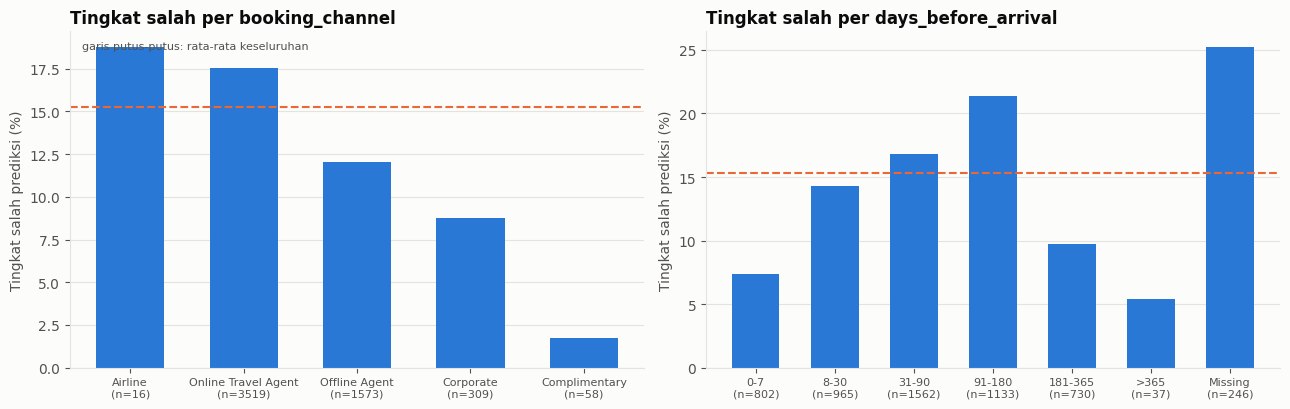

Disimpan: output/figures/error_analysis_rates.png
Contoh pembatalan yang terlewat (FN) dengan lead time panjang:


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,nightly_rate_idr,special_requests,meal_package,room_category,booking_channel
5139,1.0,0.0,2,0,0.0,389.0,1491000.0,1.0,Half Board,Type B,Offline Agent
592,1.0,0.0,2,2,0.0,360.0,1529000.0,0.0,Breakfast,Type B,Online Travel Agent
1363,1.0,0.0,0,2,0.0,344.0,1498000.0,0.0,Half Board,Type B,Offline Agent
2791,2.0,0.0,0,3,0.0,294.0,1279000.0,1.0,Room Only,Type B,Online Travel Agent
1724,1.0,0.0,0,1,0.0,286.0,0.0,0.0,Breakfast,Type B,Online Travel Agent


In [72]:
# Model final versi hold-out (di-fit pada X_clean) dianalisis pada val_set. Model submission di-fit ulang pada
# seluruh train.csv, termasuk val_set, sehingga tidak bisa dinilai di val_set.
ea_pred = np.asarray(final_spec["val_pred"]).astype(int)
y_true_va = y_va.to_numpy()
print(f"Model: {FINAL_MODEL_NAME} | Macro F1 hold-out {macro_f1(y_true_va, ea_pred):.4f}")
print(pd.DataFrame(confusion_matrix(y_true_va, ea_pred), index=["aktual 0", "aktual 1"], columns=["prediksi 0", "prediksi 1"]))
report = classification_report(y_true_va, ea_pred)
print(f"F1 kelas 0: {report['0']['f1-score']:.4f} | F1 kelas 1: {report['1']['f1-score']:.4f} | "
      f"recall kelas 1: {report['1']['recall']:.4f} | precision kelas 1: {report['1']['precision']:.4f}")

kind = np.select([(ea_pred == 1) & (y_true_va == 0), (ea_pred == 0) & (y_true_va == 1)], ["FP", "FN"], default="benar")
errors = X_va.reset_index(drop=True).assign(aktual=y_true_va, prediksi=ea_pred, jenis=kind)
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", ">365"]
errors["rentang_days_before_arrival"] = (
    pd.cut(errors["days_before_arrival"], [-np.inf, 7, 30, 90, 180, 365, np.inf], labels=lead_labels)
    .astype(object).where(errors["days_before_arrival"].notna(), "Missing")
)
errors["booking_channel"] = errors["booking_channel"].fillna("Missing")
errors["special_requests_grup"] = np.where(errors["special_requests"].isna(), "Missing",
                                           np.where(errors["special_requests"] > 0, ">0", "0"))
overall_error = float(np.mean(errors["jenis"] != "benar"))


def error_table(col, order=None):
    table = pd.crosstab(errors[col], errors["jenis"]).reindex(columns=["benar", "FP", "FN"], fill_value=0)
    table["n"] = table.sum(axis=1)
    table["tingkat_batal_aktual"] = errors.groupby(col)["aktual"].mean()
    table["tingkat_salah"] = (table["FP"] + table["FN"]) / table["n"]
    table["porsi_FN_dari_salah"] = table["FN"] / (table["FP"] + table["FN"]).replace(0, np.nan)
    return table.reindex(order) if order is not None else table.sort_values("tingkat_salah", ascending=False)


channel_errors = error_table("booking_channel")
lead_errors = error_table("rentang_days_before_arrival", lead_labels + ["Missing"])
request_errors = error_table("special_requests_grup", ["0", ">0", "Missing"])
print(f"\nTingkat kesalahan keseluruhan: {overall_error:.4f}")
for title, table in [("booking_channel", channel_errors), ("rentang days_before_arrival", lead_errors),
                     ("special_requests", request_errors)]:
    print(f"\n--- Per {title}")
    print(table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, table, title in [(axes[0], channel_errors, "booking_channel"), (axes[1], lead_errors, "days_before_arrival")]:
    pos = np.arange(len(table))
    ax.bar(pos, table["tingkat_salah"] * 100, width=0.6, color=BLUE)
    ax.axhline(overall_error * 100, color=ORANGE, linewidth=1.5, linestyle="--")
    ax.set_xticks(pos, [f"{k}\n(n={n})" for k, n in zip(table.index, table["n"])], fontsize=8)
    ax.set_ylabel("Tingkat salah prediksi (%)")
    ax.set_title(f"Tingkat salah per {title}")
    ax.grid(axis="x", visible=False)
axes[0].annotate("garis putus-putus: rata-rata keseluruhan", (0.02, 0.97), xycoords="axes fraction",
                 fontsize=8, color=MUTED, va="top")
fig.tight_layout()
save_fig(fig, "error_analysis_rates")

print("Contoh pembatalan yang terlewat (FN) dengan lead time panjang:")
errors.loc[(errors["jenis"] == "FN"), NUMERICAL_COLS[:6] + ["nightly_rate_idr", "special_requests"] + CATEGORICAL_COLS] \
    .sort_values("days_before_arrival", ascending=False).head(5)

### Ringkasan Error Analysis

- Decision Tree tuned salah pada 15,3% `val_set` (429 FP dan 408 FN). Jumlah FP dan FN hampir seimbang karena
  threshold 0.33 dipilih untuk Macro F1, bukan untuk akurasi.
- **Kanal pemesanan**: Online Travel Agent paling sering salah (17,5% dari 3.519 pemesanan) dan juga kanal dengan
  tingkat batal tertinggi. Corporate dan Complimentary jarang salah karena hampir tidak pernah batal; kesalahan
  Corporate didominasi FN. Airline hanya 16 pemesanan sehingga angkanya tidak stabil.
- **Lead time** (`days_before_arrival`): kesalahan tertinggi ada di 91–180 hari (21,4%), rentang dengan tingkat batal
  mendekati 50% sehingga kelas paling sulit dipisahkan. Pemesanan 0–7 hari jarang salah (7,4%), tetapi hampir semua
  kesalahannya FN, yaitu pembatalan mendadak yang tidak terdeteksi. Lead time di atas 180 hari mudah karena sebagian
  besar memang batal. Baris dengan lead time kosong paling sering salah (25,2%), tanda bahwa fitur ini paling
  informatif dan nilai kosongnya sulit digantikan.
- **Permintaan khusus**: pada pemesanan dengan `special_requests > 0`, 85% kesalahan adalah FN. Model cenderung
  menganggap tamu dengan permintaan khusus tidak akan batal.
- Arah perbaikan: fitur interaksi lead time dengan kanal, threshold per segmen lead time, atau ensemble Decision Tree
  dengan SVM dan KNN yang skor hold-out-nya berdekatan. Dari sisi biaya (FP = 2, FN = 1), threshold hasil
  `tune_threshold` menurunkan cost hold-out dari 1266 menjadi 1106 dengan Macro F1 turun dari 0.8270 ke 0.7951.